# Pandas review: understand, practice, explain

An executable review of DMA Lectures 16–20 and their restaurant case, with applied pandas material from Lectures 10–14, 21–22, 25, 31–32. English is the main language; short Chinese notes explain traps. All datasets below are **small synthetic teaching fixtures**, not real restaurant records.

**Learning objectives:** reason about labels, positions, shapes and row granularity; select and update safely; summarize with explicit missing-value rules; clean text and dates; combine tables without accidental weighting; group and compare observations; exchange data with files and SQLite.

**Prerequisites:** Python variables, lists, dictionaries, functions and basic comparisons. Work through Chapters 1–14 first; Chapter 15 is an optional applied lab. Allow several study sessions; Run All itself takes well under a minute on a typical laptop.

**Run instructions:** use Python 3.12 and pandas 3.0 (DataFrame.map requires pandas ≥2.1). This notebook was validated with Python 3.12.14, pandas 3.0.6, NumPy 2.5.3 and Matplotlib 3.11.2. In your usual conda environment run `conda activate myenv312`, install missing packages with `python -m pip install pandas numpy matplotlib ipykernel nbformat nbclient`, then select the **myenv312** Jupyter kernel. On your Mac, the interpreter is `/Users/leoliu/miniconda3/envs/myenv312/bin/python`; that is an environment setting, never a dataset path. Cloud validation uses an isolated Python 3.12 environment also named myenv312 because conda is unavailable here.

Open from anywhere in this repository, choose **Restart Kernel and Run All**. There are no downloads, credentials or database servers. Format demonstrations use temporary directories and an in-memory SQLite database. Run setup once; every chapter recreates its own data. Within a chapter run examples in order. Exercise starters contain comments and fresh fixtures only, so unchanged exercises do not interrupt Run All. All numbered answers, explanations and checks are together at the very end. Avoid reading that section until you have tried the questions.

## Table of contents

1. [Objects, syntax and the unit of a row](#s1)
2. [Inspect before calculating](#s2)
3. [Labels, positions, slices and return shapes](#s3)
4. [Vectorization, alignment and Boolean questions](#s4)
5. [Modify safely and keep state predictable](#s5)
6. [Summaries, missing-value rules and ordering](#s6)
7. [Missing values and repeated records](#s7)
8. [Apply the right kind of function](#s8)
9. [Text cleaning and structured strings](#s9)
10. [Types, bins and calendars](#s10)
11. [Rename, reindex and hierarchical labels](#s11)
12. [Combine tables without losing the meaning of rows](#s12)
13. [Split–aggregate–reshape and ordered histories](#s13)
14. [Capstone: restaurant inspections and honest denominators](#s14)
15. [Optional applied lab: plots, encoding, SQL and file formats](#s15)

[API coverage index](#api-index) · [All answers and explanations](#answers)

**Study route:** 1–5 foundations and safe operations → 6–10 analysis and cleaning → 11–13 keys and grouping → 14 integrated case → 15 applied lab. There are 27 exercises, E01–E27.

### Sources and corrections

Based on the course notebooks at repository main commit `b55ba349148ac464b72fd4a3cda4877c2699c3aa`:

- [Lecture 16, Series and DataFrames](lecture-16-pandas-part-1-series-and-dataframes.ipynb) and the overlapping [Lecture 16 original](lecture-16-pandas-part-1.ipynb), consolidated here.
- [Lecture 17, selecting/updating](lecture-17-pandas-part-2-selecting-adding-and-updating-data.ipynb), [18, functions/statistics](lecture-18-pandas-part-3-applying-functions-and-summary-statistics.ipynb), [19, cleaning/joining](lecture-19-pandas-part-4-cleaning-transforming-and-joining-data.ipynb), [20, indexes/grouping](lecture-20-pandas-part-5-indexes-hierarchical-indexes-and-grouping.ipynb).
- [Restaurant inspection case](new%20material/pandas-case-study-nyc-restaurant-inspections.ipynb), adapted with a synthetic snapshot so the review stays small and independent of local CSVs.
- Applied sources: Lectures 10 (CSV), 11 (statistics), 12 (correlation/histograms), 14 (Stata/dummies), 21 (cross join), 22 (SQL), 25 (decomposition), 31 (XML/JSON/fixed-width), 32 (document-shaped export/persistence). See Chapter 15 for links.

This review corrects legacy positional Series indexing, axis explanations, standard-deviation defaults, text describe behavior, Copy-on-Write updates and inspection denominators. See the [pandas user guide](https://pandas.pydata.org/docs/user_guide/index.html) for APIs beyond the course.

In [1]:
import sys
from io import StringIO
from pathlib import Path
from tempfile import TemporaryDirectory
import sqlite3
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")  # reproducible noninteractive rendering
import matplotlib.pyplot as plt
from IPython.display import display, Image

assert tuple(map(int, pd.__version__.split('.')[:2])) >= (2, 1)
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | NumPy {np.__version__}")

def shop_fixture():
    # One row = one shop. IDs are strings so leading zeroes survive.
    return pd.DataFrame({
        'shop_id': ['001', '002', '003', '004'],
        'city': ['NY', 'NY', 'LA', None],
        'sales': [10.0, 20.0, np.nan, 40.0],
        'cost': [4.0, 8.0, 3.0, 16.0],
        'opened': ['2024-01-01', '2024-02-15', 'bad', '2024-04-01']
    }, index=['a', 'b', 'c', 'd'])

def rain_fixture():
    return pd.DataFrame({'Jun': [2.0, 4.0], 'Jul': [6.0, 8.0]}, index=['NY', 'LA'])

Python 3.12.14 | pandas 3.0.6 | NumPy 2.5.3


In [2]:
def inspection_fixture():
    # Repeated names, repeated scores, zero-violation and invalid-date rows are deliberate.
    return pd.DataFrame([
        ['101',"JOE'S PIZZA",'10003','2024-01-10',20.,'08A','Critical','Cycle / Initial'],
        ['101',"JOE'S PIZZA",'10003','2024-01-10',20.,'02B','Not Critical','Cycle / Initial'],
        ['101',"JOE'S PIZZA",'10003','2024-02-10',10.,'02B','Not Critical','Cycle / Re-inspection'],
        ['102',"JOE'S PIZZA",'10003','2024-01-15',30.,'08A','Critical','Cycle / Initial'],
        ['102',"JOE'S PIZZA",'10003','2024-01-15',30.,'08A','Critical','Cycle / Initial'],
        ['103','TEA HOUSE','10012','2024-01-20',5.,None,'Not Critical','Cycle / Initial'],
        ['104','NEW CAFE','10012','1900-01-01',np.nan,None,None,None],
        ['105','BAD DATE','10012','bad',np.nan,None,None,None],
        ['106','NO DATE','10012',None,np.nan,None,None,None],
    ], columns=['camis','dba','zipcode','inspection_date','score','violation_code','critical_flag','inspection_type'])

def clean_inspections():
    data = inspection_fixture()
    data['inspection_date'] = pd.to_datetime(data['inspection_date'], format='%Y-%m-%d', errors='coerce')
    valid = data.loc[data['inspection_date'].notna() & (data['inspection_date'].dt.year > 1900)].copy()
    return valid

<a id="s1"></a>
## 1. Objects, syntax and the unit of a row

A **Series** is one-dimensional labeled data. A **DataFrame** is a table of Series sharing row labels; different columns can have different dtypes. An **Index** stores axis labels: both rows and columns have one. Its elements are immutable, although you can replace the whole index. A dtype is the storage/interpretation of values, not their business meaning. Store IDs as strings, even when they contain digits.

First ask **what does one row represent?** Here it is one shop. In the capstone it starts as one violation record: counting rows will then answer a different question from counting shops or inspections.

Read syntax before memorizing methods: `pd.Series(...)` is a constructor/function; `s.mean()` is a method; `s.dtype` is a property; `df.loc[...]` is an indexer; `s.str.lower()` and `dates.dt.year` use accessors. Parentheses call functions, square brackets select data. Most methods return another object; assignments and `del` change the target. Never assume a displayed transformation saved itself.

中文：标签是名字，位置是从 0 开始的顺序；dtype 是类型，业务 ID 是含义。先确定“一行是什么”，再决定怎么算。

| API | Object / input and purpose | Key arguments → return |
|---|---|---|
| `pd.Series` | sequence / dict → labeled one-dimensional data | data, index, dtype, name → Series |
| `pd.DataFrame` | dict of columns / records / 2-D data → table | data, index, columns, dtype → DataFrame |
| `index / columns` | Series or DataFrame row labels / DataFrame column labels | properties → Index; columns also an Index |
| `dtype / dtypes` | Series storage type / DataFrame per-column storage types | properties → dtype / Series of dtypes |
| `Series.name` | name a measure or inspect its column name | property → name scalar |

In [3]:
s = pd.Series({'b': 8, 'a': 7}, index=['a', 'b', 'c'], dtype='Float64', name='points')
df = shop_fixture()
display(s, df)
print(type(s).__name__, type(df).__name__, type(df.index).__name__)
print('labels:', df.index.tolist(), 'columns:', df.columns.tolist())
print('Series name/type:', s.name, s.dtype)
display(df.dtypes)
assert pd.isna(s.loc['c'])

a     7.0
b     8.0
c    <NA>
Name: points, dtype: Float64

,shop_id,city,sales,cost,opened
a,001,NY,10.0,4.0,2024-01-01
b,002,NY,20.0,8.0,2024-02-15
c,003,LA,NaN,3.0,bad
d,004,NaN,40.0,16.0,2024-04-01


Series DataFrame Index
labels: ['a', 'b', 'c', 'd'] columns: ['shop_id', 'city', 'sales', 'cost', 'opened']
Series name/type: points Float64


shop_id        str
city           str
sales      float64
cost       float64
opened         str
dtype: object

### Exercise E01 — Build and interpret

Create a Series named `points` with values 5 and 9 at labels `x` and `y`, using nullable integer dtype `Int64`. Build a two-column DataFrame with `points` and `passed` (False, True). Identify the row unit, index type and each dtype.

[Answer E01](#answer-e01) is in the final section.

In [4]:
# E01: write your solution below. This starter is safe to run unchanged.
pass

<a id="s2"></a>
## 2. Inspect before calculating

Look at a few rows, dimensions and dtypes before analyzing. `head`/`tail` preserve original labels; shape counts rows and columns without scanning every value. `values` removes labels and may coerce mixed columns to a common dtype or expose an extension array for a Series. Prefer the supplementary `to_numpy()` when you explicitly need a NumPy array. Neither is a route for updating the original: pandas 3 Copy-on-Write can expose read-only arrays. Transposing swaps axes and can coerce mixed dtypes.

| API | Object / input and purpose | Key arguments → return |
|---|---|---|
| `head / tail` | Series or DataFrame → preview beginning / end | n=5 → same object kind, up to n rows |
| `shape` | Series or DataFrame dimensions | property → (n,) / (rows, columns) |
| `values` | Series or DataFrame data without labels | property → ndarray or Series extension array |
| `tolist` | Series or Index → ordinary Python values | no arguments → list |
| `T` | DataFrame → swap rows and columns | property → transposed DataFrame |
| `info [supplementary]` | DataFrame schema and nonmissing counts | prints report; returns None |
| `to_numpy [supplementary]` | Series or DataFrame → explicit NumPy conversion | dtype, copy → ndarray |

In [5]:
df = shop_fixture()
display(df.head(2), df.tail(1))
print('shape:', df.shape, 'Series shape:', df['sales'].shape)
print('Series values:', df['sales'].values, 'list:', df['shop_id'].tolist())
print('DataFrame values shape:', df.values.shape)
print('NumPy shape:', df[['sales', 'cost']].to_numpy().shape)
display(df[['sales', 'cost']].T)
df.info()
# Display settings are temporary and restored on leaving the context.
with pd.option_context('display.max_rows', 6, 'display.max_columns', 8):
    display(df)

,shop_id,city,sales,cost,opened
a,001,NY,10.0,4.0,2024-01-01
b,002,NY,20.0,8.0,2024-02-15


,shop_id,city,sales,cost,opened
d,004,NaN,40.0,16.0,2024-04-01


shape: (4, 5) Series shape: (4,)
Series values: [10. 20. nan 40.] list: ['001', '002', '003', '004']
DataFrame values shape: (4, 5)
NumPy shape: (4, 2)


,a,b,c,d
sales,10.0,20.0,NaN,40.0
cost,4.0,8.0,3.0,16.0


<class 'pandas.DataFrame'>
Index: 4 entries, a to d
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   shop_id  4 non-null      str    
 1   city     3 non-null      str    
 2   sales    3 non-null      float64
 3   cost     4 non-null      float64
 4   opened   4 non-null      str    
dtypes: float64(2), str(3)
memory usage: 364.0+ bytes


,shop_id,city,sales,cost,opened
a,001,NY,10.0,4.0,2024-01-01
b,002,NY,20.0,8.0,2024-02-15
c,003,LA,NaN,3.0,bad
d,004,NaN,40.0,16.0,2024-04-01


### Exercise E02 — Preview and transpose

Using a fresh shop fixture, select the last two rows, report shape, and transpose only sales/cost. Explain why transposing all columns can change types.

[Answer E02](#answer-e02) is in the final section.

In [6]:
# E02: write your solution below. This starter is safe to run unchanged.
e02 = shop_fixture()

<a id="s3"></a>
## 3. Labels, positions, slices and return shapes

Use `loc` for labels and `iloc` for zero-based positions. Integer labels remain labels: **pandas 3 does not use `s[1]` as a positional fallback**. Label slices include the end; positional slices exclude it. Label slicing assumes suitable ordering and unambiguous endpoints; sort or select an explicit list when needed.

With unique labels, a scalar row/column pair gives a scalar. A single row or single column gives a Series; a list keeps an axis and yields a DataFrame. Duplicate labels can make a nominally single-label lookup return multiple rows. Chinese: `df['sales']` 是 Series；`df[['sales']]` 保留二维表；`loc` 可能因重复标签返回多行。

| API | Object / input and purpose | Key arguments → return |
|---|---|---|
| `[] / [[]]` | DataFrame column selection; Series label selection | single column label → Series; list of columns → DataFrame |
| `loc` | Series/DataFrame label selection and updates | row labels/mask, column labels → scalar, Series or DataFrame |
| `iloc` | Series/DataFrame position selection | integer/list/slice, column positions → shape depends on selector |

In [7]:
df = shop_fixture()
print('scalar:', df.loc['b', 'sales'], df.iloc[1, 2])
print('types:', type(df['sales']).__name__, type(df[['sales']]).__name__)
display(df.loc['a':'c', ['shop_id', 'sales']], df.iloc[:3, [0, 4]])
assert df.iloc[:3, [0, 4]].columns.tolist() == ['shop_id', 'opened']  # FIRST and FIFTH
assert df.loc['a':'c'].shape[0] == 3 and df.iloc[0:2].shape[0] == 2
display(df.loc['b'], df.loc[['b']])
integers = pd.Series([100, 200], index=[1, 0])
print('label 1:', integers.loc[1], 'position 1:', integers.iloc[1])
dup = pd.Series([7, 8, 9], index=['NY', 'NY', 'LA'])
display(dup.loc['NY'])
assert len(dup.loc['NY']) == 2

scalar: 20.0 20.0
types: Series DataFrame


,shop_id,sales
a,001,10.0
b,002,20.0
c,003,NaN


,shop_id,opened
a,001,2024-01-01
b,002,2024-02-15
c,003,bad


shop_id           002
city               NY
sales            20.0
cost              8.0
opened     2024-02-15
Name: b, dtype: object

,shop_id,city,sales,cost,opened
b,002,NY,20.0,8.0,2024-02-15


label 1: 100 position 1: 200


NY    7
NY    8
dtype: int64

### Exercise E03 — Select with intent

From a fresh shop fixture select rows b through d inclusive and columns city/sales using loc. Reproduce it using iloc. Obtain b sales once as a scalar and once as a 1×1 DataFrame.

[Answer E03](#answer-e03) is in the final section.

In [8]:
# E03: write your solution below. This starter is safe to run unchanged.
e03 = shop_fixture()

<a id="s4"></a>
## 4. Vectorization, alignment and Boolean questions

Vectorized arithmetic acts on an entire column. Series arithmetic aligns **labels**, not positions: unmatched labels usually create missing results. A scalar broadcasts. `add(fill_value=...)` makes a chosen missing-label policy explicit. Do not assume comparison between differently labeled Series aligns like addition; align deliberately first.

A comparison returns a Boolean mask. Combine masks using `&`, `|`, `~`, with parentheses around each comparison. Python `and`/`or` ask for a single truth value and fail on a Series. A mask derived from the same DataFrame shares its index. `any(axis=0)` asks whether any row is True in each column; `any(axis=1)` asks whether any column is True in each row. For reductions, think “collapse this axis.” 中文：axis=0 沿行向下算，留下每列结果；axis=1 横向算，留下每行结果。

| API | Object / input and purpose | Key arguments → return |
|---|---|---|
| `add` | Series/DataFrame aligned elementwise addition | other, axis, fill_value → new Series/DataFrame |
| `isin` | Series/Index membership test | list-like values → Boolean Series/array |
| `any` | Boolean Series/DataFrame → whether any value is True | axis, skipna → scalar or Series |

In [9]:
a = pd.Series([1, 2], index=['x', 'y'])
b = pd.Series([10, 20], index=['y', 'z'])
display(a + b, a.add(b, fill_value=0), a * 2)
df = shop_fixture()
mask = (df['sales'] >= 20) & (df['city'].isin(['NY', 'LA']))
display(df.loc[mask, ['shop_id', 'city', 'sales']])
display(df.loc[(df['sales'] > 30) | (df['city'] == 'LA')])
display(df.loc[~df['city'].isin(['NY'])])
flags = df[['sales', 'cost']] > 15
print('any at all:', flags.any().any())
display(flags.any(axis=0), flags.any(axis=1))
assert mask.index.equals(df.index)

x     NaN
y    12.0
z     NaN
dtype: float64

x     1.0
y    12.0
z    20.0
dtype: float64

x    2
y    4
dtype: int64

,shop_id,city,sales
b,002,NY,20.0


,shop_id,city,sales,cost,opened
c,003,LA,NaN,3.0,bad
d,004,NaN,40.0,16.0,2024-04-01


,shop_id,city,sales,cost,opened
c,003,LA,NaN,3.0,bad
d,004,NaN,40.0,16.0,2024-04-01


any at all: True


sales    True
cost     True
dtype: bool

a    False
b     True
c    False
d     True
dtype: bool

### Exercise E04 — Filter and align

Select shops with city NY OR cost > 10, excluding shop_id 001. Then add Series {x:2,y:3} and {y:10,z:20}, treating absent labels as zero. Predict both outputs before running.

[Answer E04](#answer-e04) is in the final section.

In [10]:
# E04: write your solution below. This starter is safe to run unchanged.
e04 = shop_fixture()

<a id="s5"></a>
## 5. Modify safely and keep state predictable

Column assignment has three meanings: a scalar repeats, a list assigns in row order and must have the right length, a Series aligns on row labels (extra labels are ignored; absent ones become missing). `assign` returns a new DataFrame and is convenient in a chain; keyword callables receive that DataFrame.

Use `df.loc[mask, 'column'] = value` to update the original in one operation. Under pandas 3 Copy-on-Write, chained assignment cannot update the original. A selected object is logically independent when written to. `copy()` makes your intent clear, although nested Python objects inside object columns are not recursively copied. Methods normally return results; many `inplace=True` methods mutate and return **None**, so never write `df = df.drop(..., inplace=True)`.

| API | Object / input and purpose | Key arguments → return |
|---|---|---|
| `column assignment / loc update` | DataFrame → add/replace column or selected cells | scalar / same-length list / aligned Series → mutation |
| `assign` | DataFrame → named new/replaced columns | keyword values or callables → new DataFrame |
| `copy` | Series/DataFrame → explicit independent working object | deep=True default → same object kind |
| `drop` | Series/DataFrame → remove labeled rows or columns | index/columns or labels+axis; inplace → object or None |
| `del` | Python statement removes a DataFrame column | del df[column] → mutation, no return |

In [11]:
df = shop_fixture()
work = df.copy()
work['flag'] = 1
work['rank'] = [4, 3, 2, 1]
work['bonus'] = pd.Series({'d': 5.0, 'a': 2.0, 'extra': 99.0})
work.loc[work['sales'] > 25, 'sales'] = 25.0
chained = work.assign(profit=lambda x: x['sales'] - x['cost']).drop(columns=['flag'])
display(chained)
assert pd.isna(work.loc['b', 'bonus']) and df.loc['d', 'sales'] == 40
# These demonstrate independent selection and explicit in-place return behavior.
selected = df[['sales']]
selected.loc['a', 'sales'] = 999.0
assert df.loc['a', 'sales'] == 10
small = df.drop(index=['d']).drop('opened', axis=1)
del small['city']
result = small.drop(columns=['cost'], inplace=True)
assert result is None
display(small)

,shop_id,city,sales,cost,opened,rank,bonus,profit
a,001,NY,10.0,4.0,2024-01-01,4,2.0,6.0
b,002,NY,20.0,8.0,2024-02-15,3,NaN,12.0
c,003,LA,NaN,3.0,bad,2,NaN,NaN
d,004,NaN,25.0,16.0,2024-04-01,1,5.0,9.0


,shop_id,sales
a,001,10.0
b,002,20.0
c,003,NaN


### Exercise E05 — A safe update pipeline

Copy the fixture; cap sales above 20 at 20 using one loc assignment. Add net=sales-cost with assign, drop opened, and verify the original fixture still has d sales=40.

[Answer E05](#answer-e05) is in the final section.

In [12]:
# E05: write your solution below. This starter is safe to run unchanged.
e05 = shop_fixture()

<a id="s6"></a>
## 6. Summaries, missing-value rules and ordering

Reduce a Series to a scalar or a DataFrame along an axis to a Series. Most numeric reductions skip missing values by default. `count` counts observed values, `nunique` counts distinct observed values, and row count is `len(df)` or GroupBy.size. They answer different questions.

`std` and `var` default to **ddof=1**, dividing squared deviations by n−1. NumPy on an array defaults to ddof=0. State your convention. `describe` for numbers reports sample standard deviation and quartiles; strings **also support describe**, returning count/unique/top/freq. A custom `sum(group)/len(group)` is not a general substitute for mean with missing values.

Use `idxmin`/`idxmax` for the **label** of the first extreme, not the value or positional number. Handle empty/all-missing data first. Sort values for rankings and sort_index for labels; missing values sort last by default. Rounding changes stored result values; it does not improve measurement precision.

| API | Object / input and purpose | Key arguments → return |
|---|---|---|
| `sum / prod` | numeric Series/DataFrame → total / product | axis, skipna, min_count → scalar/Series; default empty sum=0, prod=1 |
| `mean / median` | numeric Series/DataFrame → arithmetic center / middle | axis, skipna → scalar/Series |
| `std / var` | numeric Series/DataFrame → spread / squared spread | axis, skipna, ddof=1 → scalar/Series |
| `min / max` | Series/DataFrame → smallest / largest observed value | axis, skipna → scalar/Series |
| `idxmin / idxmax` | Series/DataFrame → label of first extreme | axis, skipna → label/Series of labels |
| `count / nunique` | Series/DataFrame → observed count / distinct count | axis; nunique(dropna=True) → scalar/Series |
| `value_counts` | Series → frequencies of values | normalize=False, dropna=True → Series |
| `describe` | Series/DataFrame → dtype-dependent summary | include, percentiles → Series/DataFrame |
| `round` | numeric Series/DataFrame → rounded values | decimals (DataFrame also dict) → new object |
| `sort_values` | Series/DataFrame → reorder by data | by for DataFrame, ascending, na_position → same object kind |
| `sort_index` | Series/DataFrame → reorder axis labels | axis, ascending → same object kind |

In [13]:
s = pd.Series([2.0, 4.0, np.nan, 4.0], index=['a', 'b', 'c', 'd'])
summary = {name: getattr(s, name)() for name in
           ['sum', 'prod', 'mean', 'median', 'std', 'var', 'min', 'max', 'idxmin', 'idxmax', 'count', 'nunique']}
display(pd.Series(summary, name='result'))
assert s.sum() == 10 and s.prod() == 32 and s.idxmax() == 'b'
assert s.count() == 3 and s.nunique() == 2
observed = s.dropna().to_numpy()
assert np.isclose(s.std(ddof=0), np.std(observed))
print('sample std:', s.std(), 'population std:', np.std(observed))
print('Python sum/len:', sum(s) / len(s), 'pandas mean:', s.mean())
display(s.describe(), pd.Series(['tea', 'tea', 'coffee']).describe())
labels = pd.Series(['NY', 'NY', None, 'LA'])
display(labels.value_counts(dropna=False), labels.value_counts(normalize=True, dropna=False).round(2))
rain = rain_fixture()
display(rain.sum(axis=0), rain.mean(axis=1), rain.idxmin(axis=1))
display(shop_fixture().sort_values(['city', 'sales'], ascending=[True, False]))
display(s.sort_index(ascending=False))

sum            10.0
prod           32.0
mean       3.333333
median          4.0
std        1.154701
var        1.333333
min             2.0
max             4.0
idxmin            a
idxmax            b
count             3
nunique           2
Name: result, dtype: object

sample std: 1.1547005383792515 population std: 0.9428090415820634
Python sum/len: nan pandas mean: 3.3333333333333335


count    3.000000
mean     3.333333
std      1.154701
min      2.000000
25%      3.000000
50%      4.000000
75%      4.000000
max      4.000000
dtype: float64

count       3
unique      2
top       tea
freq        2
dtype: object

NY     2
NaN    1
LA     1
Name: count, dtype: int64

NY     0.50
NaN    0.25
LA     0.25
Name: proportion, dtype: float64

Jun     6.0
Jul    14.0
dtype: float64

NY    4.0
LA    6.0
dtype: float64

NY    Jun
LA    Jun
dtype: str

,shop_id,city,sales,cost,opened
c,003,LA,NaN,3.0,bad
b,002,NY,20.0,8.0,2024-02-15
a,001,NY,10.0,4.0,2024-01-01
d,004,NaN,40.0,16.0,2024-04-01


d    4.0
c    NaN
b    4.0
a    2.0
dtype: float64

### Exercise E06 — Counts and denominators

For Series [10, 10, 30, missing] report count, nunique, mean and value_counts(normalize=True) both with and without dropna=False. Explain why the proportion of 10 changes.

[Answer E06](#answer-e06) is in the final section.

In [14]:
# E06: write your solution below. This starter is safe to run unchanged.
e06 = pd.Series([10.0, 10.0, 30.0, np.nan])

### Exercise E07 — Choose the statistic

For the rainfall fixture compute each city’s total, mean, sample variance, standard deviation, min, max and month of max. Sort totals descending; check that variance equals std squared.

[Answer E07](#answer-e07) is in the final section.

In [15]:
# E07: write your solution below. This starter is safe to run unchanged.
e07 = rain_fixture()

<a id="s7"></a>
## 7. Missing values and repeated records

Missing values include np.nan, pd.NA, None and datetime NaT; their exact representation depends on dtype. Test with isna rather than equality. isnull is an alias of isna; notnull aliases notna. A blank string or a 1900 placeholder date is not automatically missing.

Dropping and filling encode assumptions. `dropna(subset=...)` can require only essential fields; `how='all'` drops only entirely missing rows/columns. A scalar fill uses one value; a dict fills named columns differently. ffill/bfill depend on order, can leave edge gaps and must not cross unrelated entities. They are mechanical fills, not a general statistical imputation strategy. drop_duplicates ignores the index and keeps the first matching record by default; sort first if “latest” is the policy.

| API | Object / input and purpose | Key arguments → return |
|---|---|---|
| `pd.isna / isna / isnull` | scalar or pandas object → detect missing entries | pd.isna(obj) / obj.isna() → bool or Boolean object |
| `notna / notnull` | Series/DataFrame → detect observed entries | no arguments → Boolean object |
| `dropna` | Series/DataFrame → remove missing rows/columns | axis, subset (DataFrame), how=any/all → filtered object |
| `fillna` | Series/DataFrame → fill missing entries | value scalar/dict; limit → new object |
| `ffill / bfill` | Series/DataFrame → propagate previous / next observed value | axis, limit → filled object |
| `drop_duplicates` | Series/DataFrame → retain distinct records | subset (DataFrame), keep=first/last/False → filtered object |

In [16]:
d = pd.DataFrame({'id': ['x', 'x', 'y', 'z'], 'score': [1.0, 1.0, np.nan, np.nan], 'note': ['ok', 'ok', None, 'pending']})
display(d.isna(), d.isnull(), d.notna(), d.notnull())
assert pd.isna(None) and not pd.isna('')
display(d.dropna(subset=['score']), d.dropna(axis=1, how='any'), d.dropna(how='all'))
display(d.fillna({'score': 0.0, 'note': 'unknown'}))
sequence = pd.Series([np.nan, 2.0, np.nan, 5.0, np.nan])
display(sequence.fillna(0), sequence.ffill(), sequence.bfill())
display(d.drop_duplicates(), d.drop_duplicates(subset=['id'], keep='last'), d.drop_duplicates(subset=['id'], keep=False))
assert len(d.drop_duplicates()) == 3

,id,score,note
0,False,False,False
1,False,False,False
2,False,True,True
3,False,True,False


,id,score,note
0,False,False,False
1,False,False,False
2,False,True,True
3,False,True,False


,id,score,note
0,True,True,True
1,True,True,True
2,True,False,False
3,True,False,True


,id,score,note
0,True,True,True
1,True,True,True
2,True,False,False
3,True,False,True


,id,score,note
0,x,1.0,ok
1,x,1.0,ok


,id
0,x
1,x
2,y
3,z


... (4 outputs left out)

0    2.0
1    2.0
2    5.0
3    5.0
4    NaN
dtype: float64

,id,score,note
0,x,1.0,ok
2,y,NaN,NaN
3,z,NaN,pending


,id,score,note
1,x,1.0,ok
2,y,NaN,NaN
3,z,NaN,pending


,id,score,note
2,y,NaN,NaN
3,z,NaN,pending


### Exercise E08 — Clean only what is justified

Use the provided records. Keep the last record per id (input order is version order), drop rows missing id, and fill missing score with 0. Why is this fill a business assumption?

[Answer E08](#answer-e08) is in the final section.

In [17]:
# E08: write your solution below. This starter is safe to run unchanged.

e08 = pd.DataFrame({'id': ['a', 'a', 'b', None], 'score': [2.0, 3.0, np.nan, 9.0]})

<a id="s8"></a>
## 8. Apply the right kind of function

Prefer built-in vectorized arithmetic, string methods and reductions for ordinary work. Use a callable when it expresses a rule unavailable directly. Series.map and default Series.apply process individual values; DataFrame.map processes individual cells (current API, introduced in pandas 2.1). DataFrame.apply passes a **column Series for axis=0** and a **row Series for axis=1**. The callable’s return shape controls the assembled output.

Index.map transforms labels. Mapping with a dict turns unmapped values into missing, while replace with a dict leaves them unchanged. Pandas methods, NumPy array functions and Python builtins can differ in missing-value handling and statistical defaults. 中文：map 看单个元素；DataFrame.apply 看整列或整行。能向量化时，先选向量化。

| API | Object / input and purpose | Key arguments → return |
|---|---|---|
| `Series.map` | Series values → recode by mapping or function | arg dict/Series/callable, na_action → Series |
| `Series.apply` | Series → apply a custom scalar rule by default | func, args → Series; Series-returning func can yield DataFrame |
| `DataFrame.map` | DataFrame cells → scalar function per cell | func, na_action → DataFrame |
| `DataFrame.apply` | DataFrame → function on column/row Series | func, axis=0/1, result_type → assembled Series/DataFrame |
| `Index.map` | Index labels → transformed labels | mapper callable/dict → Index (tuples may form MultiIndex) |
| `replace` | Series/DataFrame → replace whole matching values | to_replace/value or dict, regex=False → new object |

In [18]:
s = pd.Series(['NY', 'LA', 'other'])
display(s.map({'NY': 'New York'}), s.replace({'NY': 'New York'}))
nums = pd.Series([2, 3, 4])
display(nums.map(lambda x: x * 2), nums.apply(lambda x: x ** 2))
r = rain_fixture()
display(r.map(lambda x: x * 2.54), (r * 2.54))
display(r.apply(lambda column: column.max() - column.min(), axis=0))
display(r.apply(lambda row: row.max() - row.min(), axis=1))
assert r.apply(lambda column: column.sum(), axis=0).equals(r.sum(axis=0))
print(r.index.map(str.lower).tolist())
display(r.add(1).round(1))  # chain: each returned object receives the next method

0    New York
1         NaN
2         NaN
dtype: str

0    New York
1          LA
2       other
dtype: str

0    4
1    6
2    8
dtype: int64

0     4
1     9
2    16
dtype: int64

,Jun,Jul
NY,5.08,15.24
LA,10.16,20.32


,Jun,Jul
NY,5.08,15.24
LA,10.16,20.32


Jun    2.0
Jul    2.0
dtype: float64

NY    4.0
LA    4.0
dtype: float64

['ny', 'la']


,Jun,Jul
NY,3.0,7.0
LA,5.0,9.0


### Exercise E09 — Element, row or column?

On rain_fixture, compute each row’s range with apply. Convert inches to centimeters with map and with vectorized multiplication; check equality. Map NY→East with a dict and compare replace on the city labels.

[Answer E09](#answer-e09) is in the final section.

In [19]:
# E09: write your solution below. This starter is safe to run unchanged.
e09 = rain_fixture()

<a id="s9"></a>
## 9. Text cleaning and structured strings

The str accessor applies string operations while preserving labels and missingness. strip removes edge whitespace; lower/upper normalize case; title capitalizes words but can produce `Joe'S` after apostrophes. Case formatting is not identity matching. replace acts on whole values; str.replace acts on substrings. Specify regex=False for literal punctuation such as a dot or dollar sign.

split(expand=False) yields a Series of lists; expand=True yields a DataFrame of parts. str[0] can select the first character of strings or first item of lists. contains supports literal or regular-expression searches; na=False produces a usable mask even when the text is missing.

| API | Object / input and purpose | Key arguments → return |
|---|---|---|
| `str.lower / str.upper / str.title` | string Series/Index → case-normalized text | no arguments → Series/Index |
| `str.strip [supplementary]` | string Series/Index → trim edges | to_strip=None → Series/Index |
| `str.replace` | string Series/Index → substring replacement | pat, repl, regex=False → Series/Index |
| `str.split` | string Series/Index → split at delimiter | pat, n, expand=False/True → list-valued Series / DataFrame |
| `str indexing` | string/list-valued Series → character, item or slice | str[i] / str[start:stop] → Series |
| `str.contains` | string Series/Index → search mask | pat, regex=True, case, na=False → Boolean result |

In [20]:
names = pd.Series([" JOE'S PIZZA ", 'Tea.Co', None], dtype='string')
display(pd.DataFrame({'lower': names.str.strip().str.lower(), 'upper': names.str.upper(), 'title': names.str.title()}))
display(names.str.replace('.', '!', regex=False), names.replace({'Tea.Co': 'Tea Company'}))
locs = pd.Series(['New York, US', 'Seoul, KR', None], dtype='string')
parts = locs.str.split(', ', expand=False)
display(parts, parts.str[-1], locs.str.split(', ', expand=True), locs.str[0])
print('literal dot:', names.str.contains('.', regex=False, na=False).tolist())
print('regex starts J/T:', names.str.strip().str.contains(r'^[JT]', regex=True, na=False).tolist())

,lower,upper,title
0,joe's pizza,JOE'S PIZZA,Joe'S Pizza
1,tea.co,TEA.CO,Tea.Co
2,<NA>,<NA>,<NA>


0     JOE'S PIZZA 
1           Tea!Co
2             <NA>
dtype: string

0     JOE'S PIZZA 
1      Tea Company
2             <NA>
dtype: string

0    [New York, US]
1       [Seoul, KR]
2              <NA>
dtype: object

0      US
1      KR
2    <NA>
dtype: object

,0,1
0,New York,US
1,Seoul,KR
2,<NA>,<NA>


0       N
1       S
2    <NA>
dtype: string

literal dot: [False, True, False]
regex starts J/T: [True, True, False]


### Exercise E10 — Clean money and URLs

Strip and lowercase the given URLs; split once at :// into protocol and host. Remove literal dollar signs and commas from money, then convert with to_numeric(errors="coerce") (introduced next). Keep bad money missing.

[Answer E10](#answer-e10) is in the final section.

In [21]:
# E10: write your solution below. This starter is safe to run unchanged.

e10_urls = pd.Series([' HTTPS://NYU.EDU ', 'http://example.com'], dtype='string')
e10_money = pd.Series(['$1,200', '$30', 'unknown'], dtype='string')

<a id="s10"></a>
## 10. Types, bins and calendars

astype is a strict conversion when data is valid; use nullable `Int64` for integer data with missing entries. to_numeric/to_datetime with errors='coerce' expose invalid input as missing (NaN/pd.NA for numbers depending on dtype, **NaT** for dates). Inspect failures before dropping them. Explicit format helps parse known date formats; mixed date formats need an explicit policy.

cut puts continuous observations into intervals. With right=True (default), bins [0,13,27,100] mean (0,13], (13,27], (27,100]; include_lowest=True includes zero. Out-of-range data stays missing. For left-closed bins use right=False, which changes every boundary, including the last. dt properties extract numbers; dt.month_name()/day_name() are methods. ISO weeks can belong to a different ISO year than the calendar year.

| API | Object / input and purpose | Key arguments → return |
|---|---|---|
| `astype` | Series/DataFrame → change dtype | dtype or column→dtype dict → converted object (invalid raises by default) |
| `pd.to_numeric` | scalar / 1-D input → numeric values | arg, errors=raise/coerce → numeric scalar/Series/array |
| `pd.to_datetime` | date-like input → timestamps | arg, format, errors=coerce → Timestamp/Series/DatetimeIndex |
| `pd.cut` | 1-D numeric input → interval categories | bins, labels, right, include_lowest → categorical Series/Categorical |
| `dt.year / dt.month / dt.dayofyear` | datetime Series → calendar components | properties → Series |
| `dt.month_name / dt.day_name` | datetime Series → readable month/day | locale optional → Series |
| `dt.isocalendar().week` | datetime Series → ISO week | isocalendar() → DataFrame; .week → nullable-integer Series |

In [22]:
s = pd.Series(['1', 'bad', None], dtype='string')
n = pd.to_numeric(s, errors='coerce').astype('Int64')
display(n)
dates = pd.to_datetime(pd.Series(['2024-01-01', 'bad', '2024-12-31']), format='%Y-%m-%d', errors='coerce')
display(pd.DataFrame({'date': dates, 'year': dates.dt.year, 'month': dates.dt.month,
                      'ordinal_day': dates.dt.dayofyear, 'month_name': dates.dt.month_name(),
                      'weekday': dates.dt.day_name(), 'ISO_week': dates.dt.isocalendar().week}))
assert pd.isna(dates.iloc[1])
scores = pd.Series([0, 13, 14, 27, 28, 100, 101])
grade = pd.cut(scores, bins=[0, 13, 27, 100], labels=['A','B','C'], right=True, include_lowest=True)
display(pd.DataFrame({'score':scores, 'band':grade}))
left_closed = pd.cut(pd.Series([0,13,27]), bins=[0,13,27,101], labels=['low','mid','high'], right=False)
display(left_closed)

0       1
1    <NA>
2    <NA>
dtype: Int64

,date,year,month,ordinal_day,month_name,weekday,ISO_week
0,2024-01-01,2024.0,1.0,1.0,January,Monday,1
1,NaT,NaN,NaN,NaN,NaN,NaN,<NA>
2,2024-12-31,2024.0,12.0,366.0,December,Tuesday,1


,score,band
0,0,A
1,13,A
2,14,B
3,27,B
4,28,C
5,100,C
6,101,NaN


0     low
1     mid
2    high
dtype: category
Categories (3, str): ['low' < 'mid' < 'high']

### Exercise E11 — Test boundaries and failed dates

Bin [0,13,14,27,28] into A/B/C using right-closed boundaries 0,13,27,infinity and include zero. Convert ["2024-02-29","2024-02-30"] using coerce; report dayofyear and the missing-date count.

[Answer E11](#answer-e11) is in the final section.

In [23]:
# E11: write your solution below. This starter is safe to run unchanged.
e11_scores = pd.Series([0,13,14,27,28])

<a id="s11"></a>
## 11. Rename, reindex and hierarchical labels

Rename changes existing labels; reindex selects/reorders labels and can introduce new rows with missing values. Replacing index/columns assigns all labels by position and requires matching length. rename_axis names an axis itself, not its entries. set_index moves column values into the index (drop=True by default); reset_index moves them back or discards them with drop=True.

A MultiIndex stores tuples as hierarchical labels. Build it with set_index([...]) or pd.MultiIndex.from_tuples. Sort it before range selections. Use explicit `loc[(level1, level2), :]` to distinguish a row tuple from the row/column pair. Indexes, including MultiIndexes, do not enforce database uniqueness.

| API | Object / input and purpose | Key arguments → return |
|---|---|---|
| `rename` | Series/DataFrame → change labels (Series also accepts a name) | index/columns dict or function → renamed object |
| `index / columns assignment` | DataFrame/Series → replace full labels | same-length iterable → mutation |
| `reindex` | Series/DataFrame → align to requested labels | index, columns, fill_value → new object |
| `set_index` | DataFrame → column(s) become index | keys, drop=True, verify_integrity optional → DataFrame |
| `reset_index` | Series/DataFrame → index becomes columns or is discarded | drop=False, level → reset object |
| `rename_axis` | Series/DataFrame → name axes/levels | index/columns names → renamed object |
| `pd.MultiIndex.from_tuples` | sequence of label tuples → hierarchical index | tuples, names → MultiIndex |

In [24]:
df = shop_fixture()
display(df.rename(index={'a':'alpha'}, columns={'sales':'revenue'}))
display(df.rename(index=str.upper, columns=str.upper))
fresh = df.copy()
fresh.index = [10,20,30,40]
fresh.columns = fresh.columns.map(str.upper)
display(fresh.reindex(index=[40,10,99], columns=['SHOP_ID','SALES']))
keyed = df.set_index('shop_id').rename_axis('store')
display(keyed.reset_index(), keyed.reset_index(drop=True))
multi = pd.DataFrame({'year':[2024,2024,2025], 'city':['NY','LA','NY'], 'sales':[10,20,30]}).set_index(['year','city']).sort_index()
display(multi.loc[(2024,'NY'), :])
constructed = pd.MultiIndex.from_tuples([(2024,'NY'),(2025,'LA')], names=['year','city'])
print(constructed)

,shop_id,city,revenue,cost,opened
alpha,001,NY,10.0,4.0,2024-01-01
b,002,NY,20.0,8.0,2024-02-15
c,003,LA,NaN,3.0,bad
d,004,NaN,40.0,16.0,2024-04-01


,SHOP_ID,CITY,SALES,COST,OPENED
A,001,NY,10.0,4.0,2024-01-01
B,002,NY,20.0,8.0,2024-02-15
C,003,LA,NaN,3.0,bad
D,004,NaN,40.0,16.0,2024-04-01


,SHOP_ID,SALES
40,004,40.0
10,001,10.0
99,NaN,NaN


,store,city,sales,cost,opened
0,001,NY,10.0,4.0,2024-01-01
1,002,NY,20.0,8.0,2024-02-15
2,003,LA,NaN,3.0,bad
3,004,NaN,40.0,16.0,2024-04-01


,city,sales,cost,opened
0,NY,10.0,4.0,2024-01-01
1,NY,20.0,8.0,2024-02-15
2,LA,NaN,3.0,bad
3,NaN,40.0,16.0,2024-04-01


sales    10
Name: (2024, NY), dtype: int64

MultiIndex([(2024, 'NY'),
            (2025, 'LA')],
           names=['year', 'city'])


### Exercise E12 — Index round trip

Set shop_id as the fixture’s index, name the axis store_id, and reindex to 004,001,999. Reset the index into a column. Explain which row is newly introduced.

[Answer E12](#answer-e12) is in the final section.

In [25]:
# E12: write your solution below. This starter is safe to run unchanged.
e12 = shop_fixture()

<a id="s12"></a>
## 12. Combine tables without losing the meaning of rows

merge matches key values; concat stacks objects along an axis; join normally matches indexes. Choose keys before joining. Inner retains matched keys, left retains all left rows, right all right rows, outer either side’s keys; cross creates every pair and takes no on key.

A left merge can increase rows: a key appearing m times on the left and n on the right produces m×n matched rows. Supplementary validate='many_to_one' checks the right side is unique. pandas also matches missing keys to each other, unlike typical SQL NULL semantics; decide whether to drop missing keys first. Different key names require left_on/right_on; composite identities require a list of keys.

concat(axis=0) stacks rows, aligning columns by name. ignore_index=True gives new sequential row labels. concat(axis=1) aligns row indexes, not row order. Reset indexes only when positional pairing is really justified. 中文：merge 按键匹配；concat 横拼仍按行标签对齐；join 默认按索引。左连接不保证行数不变。

| API | Object / input and purpose | Key arguments → return |
|---|---|---|
| `pd.merge / DataFrame.merge` | two DataFrames → key-based combination | how, on, left_on/right_on, suffixes, validate → DataFrame |
| `pd.concat` | iterable of Series/DataFrames → stack along one axis | axis=0/1, ignore_index, join → combined object |
| `DataFrame.join` | DataFrame → join other columns using indexes by default | other, on optional left key, how, suffixes → DataFrame |

In [26]:
left = pd.DataFrame({'k':[1,2,3], 'amount':[10,20,30]})
right = pd.DataFrame({'k':[2,2,4], 'tag':['a','b','c']})
for how in ['inner','left','right','outer']:
    print(how)
    display(pd.merge(left,right,on='k',how=how))
assert len(left.merge(right, on='k', how='left')) == 4
lookup = pd.DataFrame({'code':[1,2], 'region':['East','West']})
display(left.merge(lookup, left_on='k', right_on='code', how='left', validate='many_to_one'))
display(left.head(2).merge(pd.DataFrame({'day':['Mon','Tue']}), how='cross'))
display(pd.concat([left.head(1), left.tail(1)], axis=0, ignore_index=True))
a = pd.DataFrame({'x':[1,2]}, index=['a','b'])
b = pd.DataFrame({'y':[30,40]}, index=['b','c'])
display(pd.concat([a,b],axis=1), a.join(b,how='left'))
# Composite keys: year alone would mix terms.
a = pd.DataFrame({'course':['P','P'], 'year':[2024,2025], 'n':[1,2]})
b = pd.DataFrame({'course':['P','P'], 'year':[2024,2025], 'room':['A','B']})
display(a.merge(b,on=['course','year'],validate='one_to_one'))

inner


,k,amount,tag
0,2,20,a
1,2,20,b


left


,k,amount,tag
0,1,10,NaN
1,2,20,a
2,2,20,b
3,3,30,NaN


right


,k,amount,tag
0,2,20.0,a
1,2,20.0,b
2,4,NaN,c


... (4 outputs left out)

,k,amount
0,1,10
1,3,30


,x,y
a,1.0,NaN
b,2.0,30.0
c,NaN,40.0


,x,y
a,1,NaN
b,2,30.0


,course,year,n,room
0,P,2024,1,A
1,P,2025,2,B


### Exercise E13 — Predict merge multiplicity

For left keys [1,2,2] and right keys [2,2,3], predict row counts for inner, left, right, outer and cross merges. Execute all five and verify. Why would many_to_one validation fail?

[Answer E13](#answer-e13) is in the final section.

In [27]:
# E13: write your solution below. This starter is safe to run unchanged.

e13_left = pd.DataFrame({'k':[1,2,2]})
e13_right = pd.DataFrame({'k':[2,2,3]})

### Exercise E14 — Alignment versus positional pairing

Join a={x:[1,2]} indexed a,b to b={y:[30,40]} indexed b,c. Compare index join, concat(axis=1), and concat after reset_index(drop=True) on both. State which pairing is justified by labels.

[Answer E14](#answer-e14) is in the final section.

In [28]:
# E14: write your solution below. This starter is safe to run unchanged.
pass

<a id="s13"></a>
## 13. Split–aggregate–reshape and ordered histories

GroupBy is a deferred grouping object: select columns, then choose an aggregation. Series.groupby accepts a same-index grouping Series; DataFrame.groupby accepts column names. as_index=False returns keys as columns; dropna=False keeps missing group keys. Set observed explicitly when grouping categories if you need a particular policy for unused categories.

agg and aggregate are aliases. A list applies several reductions to each selected column; a dict chooses reductions by column; named aggregation gives clear output names. A callable gets a group Series, so write a missing-aware function. size counts rows, count counts observed values per column, nunique counts distinct observed values. Boolean mean is the proportion True among nonmissing Booleans: make your missingness policy explicit.

first/last skip missing values separately in each column by default, so their output may never have existed as a complete row. For a complete latest record, sort by time (and resolve ties), then groupby.tail(1). diff compares consecutive values in the current group order; sort first. unstack moves an index level to columns; crosstab makes a count table from categorical variables. 中文：先排序再比较前后；first/last 不一定是一整条原始记录。

| API | Object / input and purpose | Key arguments → return |
|---|---|---|
| `DataFrame.groupby / Series.groupby` | table/Series → split by key(s) | by, as_index (DataFrame), dropna, observed → GroupBy |
| `agg / aggregate` | Series/DataFrame/GroupBy → one or several summaries | str, list, dict, callable, named outputs → scalar/Series/DataFrame |
| `GroupBy.size / count / nunique` | groups → rows / observed values / distinct values | nunique(dropna=True) → Series/DataFrame |
| `GroupBy.first / last` | groups → first/last nonmissing value per column | skipna=True → Series/DataFrame; may combine different rows |
| `GroupBy.tail` | groups → final n original rows in existing order | n=1 → subset with original row labels |
| `GroupBy.diff` | numeric grouped Series/DataFrame → within-group differences | periods=1 → original-length Series/DataFrame |
| `GroupBy.any` | Boolean groups → any True in group | skipna → Series/DataFrame |
| `unstack` | Series/DataFrame with MultiIndex → move level into columns | level=-1, fill_value → Series/DataFrame |
| `pd.crosstab` | categorical arrays/Series → frequency table | index, columns, normalize optional → DataFrame |

In [29]:
d = pd.DataFrame({'team':['A','A','B',None], 'person':['p','q','p','r'],
                  'points':[2.0,np.nan,6.0,8.0], 'ok':[True,False,True,True]})
g = d.groupby('team',dropna=False)
display(g['points'].agg(['sum','prod','mean','median','std','var','min','max']))
display(g.agg({'points':['mean','count'], 'person':'nunique'}))
display(d.groupby('team',as_index=False,dropna=False).agg(rows=('points','size'), measured=('points','count'), people=('person','nunique'), mean_points=('points','mean')))
display(d['points'].groupby(d['team'],dropna=False).mean())
def observed_mean(group):
    valid = group.dropna()
    return valid.sum() / len(valid) if len(valid) else np.nan
display(g['points'].aggregate(observed_mean), g['ok'].any(), g['ok'].mean())
counts = d.groupby(['team','person'],dropna=False).size()
display(counts.unstack(fill_value=0), pd.crosstab(d['team'].fillna('Unknown'),d['ok']))
# first/last may synthesize rows:
h = pd.DataFrame({'id':['x','x'], 'time':[1,2], 'a':[1.0,np.nan], 'b':[np.nan,9.0]})
display(h.groupby('id').first(), h.groupby('id').last(), h.sort_values('time').groupby('id').tail(1))
history = pd.DataFrame({'id':['x','x','y','y'], 'day':[2,1,2,1], 'score':[8.,10.,7.,5.]})
history = history.sort_values(['id','day'])
history['change'] = history.groupby('id')['score'].diff()
display(history)
assert history.loc[0,'change'] == -2

,sum,prod,mean,median,std,var,min,max
team,,,,,,,,
A,2.0,2.0,2.0,2.0,NaN,NaN,2.0,2.0
B,6.0,6.0,6.0,6.0,NaN,NaN,6.0,6.0
NaN,8.0,8.0,8.0,8.0,NaN,NaN,8.0,8.0


points        person
       mean count nunique
team                     
A       2.0     1       2
B       6.0     1       1
NaN     8.0     1       1

,team,rows,measured,people,mean_points
0,A,2,1,2,2.0
1,B,1,1,1,6.0
2,NaN,1,1,1,8.0


team
A      2.0
B      6.0
NaN    8.0
Name: points, dtype: float64

team
A      2.0
B      6.0
NaN    8.0
Name: points, dtype: float64

team
A      True
B      True
NaN    True
Name: ok, dtype: bool

... (3 outputs left out)

,time,a,b
id,,,
x,1,1.0,9.0


,time,a,b
id,,,
x,2,1.0,9.0


,id,time,a,b
1,x,2,NaN,9.0


,id,day,score,change
1,x,1,10.0,NaN
0,x,2,8.0,-2.0
3,y,1,5.0,NaN
2,y,2,7.0,2.0


### Exercise E15 — Group sizes, counts and named aggregation

On the team data below, retain missing group keys. Return team, rows, observed points, unique people and mean points as named columns. Report share ok and whether any ok per team.

[Answer E15](#answer-e15) is in the final section.

In [30]:
# E15: write your solution below. This starter is safe to run unchanged.

e15 = pd.DataFrame({'team':['A','A','B',None], 'person':['p','q','p','r'], 'points':[2.,np.nan,6.,8.], 'ok':[True,False,True,True]})

### Exercise E16 — Full latest rows and changes

Sort the history below by id/day; compute within-id score differences, and retain each id’s latest full row. Explain the negative change for x.

[Answer E16](#answer-e16) is in the final section.

In [31]:
# E16: write your solution below. This starter is safe to run unchanged.

e16 = pd.DataFrame({'id':['x','x','y','y'], 'day':[2,1,2,1], 'score':[8.,10.,7.,5.]})

### Exercise E17 — Long counts to wide table

For rows (NY,tea),(NY,tea),(NY,coffee),(LA,tea), compute counts with groupby.size then unstack(fill_value=0). Reproduce with crosstab and compare after sorting axes.

[Answer E17](#answer-e17) is in the final section.

In [32]:
# E17: write your solution below. This starter is safe to run unchanged.
pass

<a id="s14"></a>
## 14. Capstone: restaurant inspections and honest denominators

This is a **synthetic snapshot**, modeled on the course restaurant case; results describe this fixture, never live restaurant status. It contains repeated inspection scores because each recorded violation is a row. A row with no violation code can also represent a documented inspection with no listed violation. Count nonmissing violation codes if you mean recorded violations.

`camis` identifies restaurants. `dba` is a business name; two locations can share it, so unique names undercount restaurants. We assume **(camis, inspection_date)** identifies an inspection only for this fixture. In real data, check inspection type/time/other identifiers: two visits on one day may require a richer key. Before collapsing records, verify that score and other inspection-level attributes agree within the proposed key.

Plan the units: raw rows → clean records → distinct inspections → restaurant histories. Remove missing/unparseable and 1900 placeholder dates by an explicit rule. Average **one score per inspection**, not repeated violation rows; otherwise inspections with more recorded violations receive extra weight. A per-restaurant average weights restaurants differently again.

For “share of inspections with code 08A,” first compute any 08A per inspection, then average those Booleans by ZIP. Denominator: all eligible valid-date inspections, including zero-violation inspections. For score means, count observed scores and report sample sizes. Lower restaurant scores are better, so a negative score difference indicates a lower subsequent score. This is descriptive change, not causal evidence about re-inspection.

In [33]:
raw = inspection_fixture()
clean = clean_inspections()
keys = ['camis','inspection_date']
# Verify assumptions before choosing one row per inspection.
for col in ['dba','zipcode','score','inspection_type']:
    assert clean.groupby(keys)[col].nunique(dropna=False).max() == 1
inspections = clean.drop_duplicates(keys).copy()
print('raw rows:',len(raw), 'eligible rows:',len(clean), 'coded violation records:',clean['violation_code'].count())
print('restaurants:',clean['camis'].nunique(), 'names:',clean['dba'].nunique(), 'inspections:',len(inspections))
print('row-weighted score:', round(clean['score'].mean(),2), 'inspection-weighted:', round(inspections['score'].mean(),2))
assert len(inspections) == 4 and clean['camis'].nunique() == 3
assert clean['dba'].nunique() == 2 and inspections['score'].mean() == 16.25
# Code frequencies count records, including the deliberate duplicate code row.
codes = pd.DataFrame({'violation_code':['08A','02B'], 'description':['Rodent-attracting conditions','Temperature control']})
frequencies = clean['violation_code'].value_counts().rename_axis('violation_code').reset_index(name='count')
display(frequencies.merge(codes,on='violation_code',how='left',validate='many_to_one'))

raw rows: 9 eligible rows: 6 coded violation records: 5
restaurants: 3 names: 2 inspections: 4
row-weighted score: 19.17 inspection-weighted: 16.25


,violation_code,count,description
0,08A,3,Rodent-attracting conditions
1,02B,2,Temperature control


### From violation rows to per-inspection flags

The two identical 08A rows cannot affect an inspection-level `any`, but they do affect raw frequency counts. Real repeated records may be legitimate observations or ingestion duplicates; do not delete them automatically without understanding provenance. Here a whole-row duplicate is deliberately included so you can compare policies.

A count-table pipeline needs an explicit count-column name: `value_counts().rename_axis('violation_code').reset_index(name='count')`. rename_axis names the old index before it becomes the key column. A checked many-to-one merge attaches descriptions without multiplying counts.

In [34]:
clean = clean_inspections()
keys = ['camis','inspection_date']
inspections = clean.drop_duplicates(keys).copy()
flags = (clean.assign(is_08a=clean['violation_code'].eq('08A').fillna(False))
         .groupby(['zipcode',*keys],dropna=False)['is_08a'].any().reset_index())
by_zip = flags.groupby('zipcode').agg(inspections=('is_08a','size'), with_08a=('is_08a','sum'), share_08a=('is_08a','mean'))
display(by_zip)
assert np.isclose(by_zip.loc['10003','share_08a'], 2/3)
assert by_zip.loc['10012','share_08a'] == 0
# Named summaries retain sample sizes for the score denominator.
display(inspections.groupby('zipcode')['score'].agg(['mean','median','count']).round(2))
inspections['expected_band'] = pd.cut(inspections['score'], bins=[0,13,27,np.inf], labels=['A','B','C'], include_lowest=True)
inspections['weekday'] = inspections['inspection_date'].dt.day_name()
display(pd.crosstab(inspections['zipcode'],inspections['expected_band']))
history = inspections.sort_values(['camis','inspection_date'])
history['score_change'] = history.groupby('camis')['score'].diff()
latest_in_snapshot = history.groupby('camis').tail(1)
display(latest_in_snapshot[['camis','dba','inspection_date','score','score_change']])
assert history.loc[history['camis']=='101','score_change'].dropna().tolist() == [-10]

,inspections,with_08a,share_08a
zipcode,,,
10003,3,2,0.666667
10012,1,0,0.000000


,mean,median,count
zipcode,,,
10003,20.0,20.0,3
10012,5.0,5.0,1


expected_band,A,B,C
zipcode,,,
10003,1,1,1
10012,1,0,0


,camis,dba,inspection_date,score,score_change
2,101,JOE'S PIZZA,2024-02-10,10.0,-10.0
3,102,JOE'S PIZZA,2024-01-15,30.0,NaN
5,103,TEA HOUSE,2024-01-20,5.0,NaN


### Exercise E18 — Capstone A: audit before collapse

Using inspection_fixture(), parse dates and report: raw rows, valid-date nonplaceholder rows, unique restaurant IDs, unique names, distinct inspections and coded violation records. Verify the proposed inspection key gives one score per inspection. Explain why names are unsuitable as restaurant IDs.

[Answer E18](#answer-e18) is in the final section.

In [35]:
# E18: write your solution below. This starter is safe to run unchanged.
e18 = inspection_fixture()

### Exercise E19 — Capstone B: quantify duplicate weighting

Compare raw eligible-row mean score, whole-row-deduplicated mean score, inspection-level mean score and the mean of restaurant-level mean scores. Report each denominator. Which answers an equally weighted inspection question?

[Answer E19](#answer-e19) is in the final section.

In [36]:
# E19: write your solution below. This starter is safe to run unchanged.
e19 = clean_inspections()

### Exercise E20 — Capstone C: fair proportions and histories

Compute per-ZIP share of eligible inspections with any 08A; include denominator and numerator. Then show the latest full inspection row per camis and within-restaurant score change. Explain both a negative difference and why snapshot latest is not live status.

[Answer E20](#answer-e20) is in the final section.

In [37]:
# E20: write your solution below. This starter is safe to run unchanged.
e20 = clean_inspections()

<a id="s15"></a>
## 15. Optional applied lab: plots, encoding, SQL and file formats

These small examples extend the core lessons to the rest of the course. They run locally, create no persistent exports and need no model training or MongoDB server.

Sources: [10 CSV](lecture-10-extracting-data-from-a-comma-separated-values-file.ipynb), [11 summaries](lecture-11-simple-descriptive-statistics.ipynb), [12 correlation](lecture-12-covariance-and-correlation.ipynb), [14 encoding/Stata](lecture-14-logistic-regression.ipynb), [21 cross joins](lecture-21-introduction-to-databases.ipynb), [22 SQL](lecture-22-introduction-to-sqlite.ipynb), [25 record decomposition](lecture-25-motivation-for-database-design.ipynb), [31 text formats](lecture-31-text-file-formats-xml-and-json.ipynb), [32 document exports](lecture-32-introduction-to-mongodb.ipynb). Filenames reflect the repository’s lecture titles; the concepts below are self-contained.

### 15.1 CSV inputs and numeric exploration

read_csv consumes a path or text buffer and returns a DataFrame. sep changes the delimiter; dtype protects leading-zero IDs; index_col chooses labels; parse_dates parses valid date fields during reading. For invalid dates, read text and call to_datetime(errors='coerce') explicitly. to_csv(index=False) exports data without accidentally writing the row labels as another column.

corr(numeric_only=True) computes pairwise numeric correlations; missing pairs are omitted. A correlation does not show causation and can be unstable with small samples. Histograms show bin counts. We render the figures to PNG in memory with a fixed, noninteractive backend, then close them. No random data or interactive window is needed.

| API | Object / input and purpose | Key arguments → return |
|---|---|---|
| `pd.read_csv` | path or file-like text → delimiter-separated table | sep, dtype, parse_dates, index_col → DataFrame |
| `to_csv` | DataFrame → CSV serialization | path optional, index=False → file (None return) or CSV string |
| `corr` | numeric DataFrame → pairwise correlations | numeric_only=True, method, min_periods → DataFrame |
| `Series.hist / DataFrame.hist` | numeric Series/DataFrame → histogram(s) | bins, ax/figsize → Axes / array of Axes |

,day,x,y,label
id,,,,
001,2024-01-01,1,2,a
002,2024-01-02,2,4,b
003,2024-01-03,3,6,a
004,2024-01-04,4,8,b


,day,x,y
count,4,4.000000,4.000000
mean,2024-01-02 12:00:00,2.500000,5.000000
min,2024-01-01 00:00:00,1.000000,2.000000
25%,2024-01-01 18:00:00,1.750000,3.500000
50%,2024-01-02 12:00:00,2.500000,5.000000
75%,2024-01-03 06:00:00,3.250000,6.500000
max,2024-01-04 00:00:00,4.000000,8.000000
std,NaN,1.290994,2.581989


label
a    2
b    2
Name: count, dtype: int64

,x,y
x,1.0,1.0
y,1.0,1.0


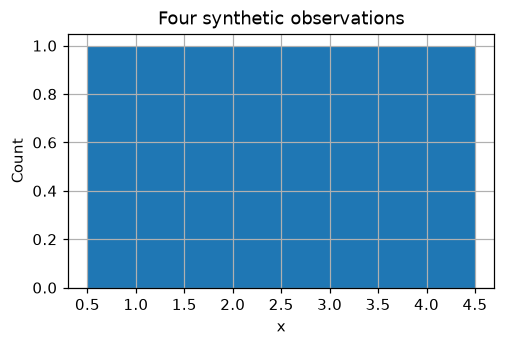

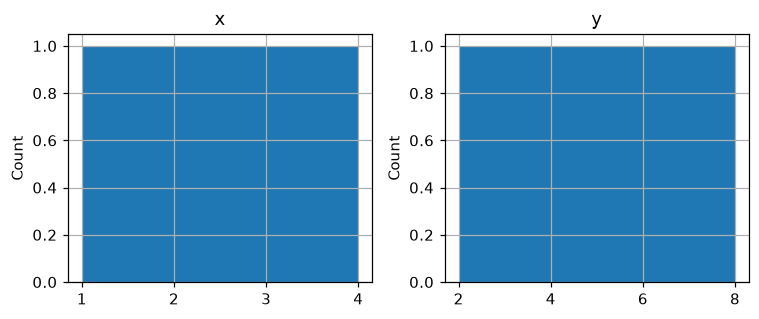

In [38]:
from io import BytesIO
csv_text = 'id;day;x;y;label\n001;2024-01-01;1;2;a\n002;2024-01-02;2;4;b\n003;2024-01-03;3;6;a\n004;2024-01-04;4;8;b\n'
lab = pd.read_csv(StringIO(csv_text), sep=';', dtype={'id':'string'}, parse_dates=['day'], index_col='id')
assert lab.index[0] == '001' and lab['day'].dt.year.iloc[0] == 2024
display(lab, lab.describe(), lab['label'].value_counts(), lab.corr(numeric_only=True))
assert np.isclose(lab.corr(numeric_only=True).loc['x','y'],1)

def show_plot(fig):
    with BytesIO() as buffer:
        fig.savefig(buffer, format='png', dpi=110, bbox_inches='tight')
        display(Image(data=buffer.getvalue()))
    plt.close(fig)

fig, ax = plt.subplots(figsize=(5,3))
lab['x'].hist(bins=[.5,1.5,2.5,3.5,4.5], ax=ax)
ax.set(title='Four synthetic observations', xlabel='x', ylabel='Count')
show_plot(fig)
axes = lab[['x','y']].hist(bins=4, figsize=(7,3))
axes.ravel()[0].set_ylabel('Count')
axes.ravel()[1].set_ylabel('Count')
axes.ravel()[0].figure.tight_layout()
show_plot(axes.ravel()[0].figure)
with TemporaryDirectory() as folder:
    path = Path(folder) / 'lab.csv'
    lab.reset_index().to_csv(path, index=False)
    restored = pd.read_csv(path, dtype={'id':'string'}, parse_dates=['day'])
    assert restored['id'].tolist() == ['001','002','003','004']

### Exercise E21 — Read a typed CSV and inspect

Read the semicolon text below with id as a string index and day parsed as datetime. Compute numeric correlation, describe the numeric columns, count kind values, and report the proportion kind A. Export to a CSV string without an index; check the header.

[Answer E21](#answer-e21) is in the final section.

In [39]:
# E21: write your solution below. This starter is safe to run unchanged.

e21_text = 'id;day;x;y;kind\n001;2024-01-01;1;3;A\n002;2024-01-02;2;6;B\n003;2024-01-03;3;9;A\n'

### 15.2 Stata, dummy variables and aligned feature tables

Read a small Stata file generated within the same temporary directory. No external Stata installation is needed. get_dummies turns categories into indicator columns; prefix controls names and dtype=int gives 0/1 integers. Missing categories are all zero unless dummy_na=True. join uses matching indexes. reset_index(drop=True) is useful for positional comparison only after confirming the rows refer to the same observations.

| API | Object / input and purpose | Key arguments → return |
|---|---|---|
| `pd.read_stata` | path/buffer to a Stata file → tabular data | columns, convert_categoricals → DataFrame |
| `pd.get_dummies` | Series/DataFrame categorical values → indicators | prefix, dtype=int, dummy_na, drop_first → DataFrame |
| `to_stata [supporting fixture writer]` | DataFrame → local Stata file | path, write_index=False → None |

In [40]:
admissions = pd.DataFrame({'id':[1,2,3], 'rank':['high','low','high'], 'gpa':[3.8,3.0,3.5]})
with TemporaryDirectory() as folder:
    path = Path(folder) / 'admissions.dta'
    admissions.to_stata(path, write_index=False)
    loaded = pd.read_stata(path)
    dummies = pd.get_dummies(loaded['rank'], prefix='rank', dtype=int)
    features = loaded[['id','gpa']].join(dummies)
    display(features)
    assert features['rank_high'].tolist() == [1,0,1]
# A positional side-by-side comparison AFTER verifying the same order/IDs.
truth = pd.Series([1,0,1], index=[10,20,30], name='truth')
prediction = pd.Series([1,1,1], index=[0,1,2], name='prediction')
comparison = pd.concat([truth.reset_index(drop=True), prediction.reset_index(drop=True)],axis=1)
display(comparison)

,id,gpa,rank_high,rank_low
0,1,3.8,1,0
1,2,3.0,0,1
2,3,3.5,1,0


,truth,prediction
0,1,1
1,0,1
2,1,1


### Exercise E22 — Encode and join

Encode rank values ["high","low","high"] with prefix rank and dtype=int, join to id values [1,2,3], and count high ranks. What happens for a missing category by default?

[Answer E22](#answer-e22) is in the final section.

In [41]:
# E22: write your solution below. This starter is safe to run unchanged.
e22 = pd.DataFrame({"id":[1,2,3],"rank":["high","low","high"]})

### 15.3 SQLite and record decomposition

Use Python’s sqlite3 connection to an in-memory database. to_sql writes a DataFrame; index=False avoids a synthetic index column, if_exists='replace' makes this demo rerunnable. read_sql_query returns the result of a SELECT and can designate an index column. The connection closes after the example.

Decomposition reduces repeated entity attributes into tables at different granularities. First check functional dependencies: the same course+year must always have the same title. drop_duplicates removes repeats but does not resolve conflicting records. Reconstruct using all parts of the key and validate relationships; then compare records after restoring a common row and column order.

| API | Object / input and purpose | Key arguments → return |
|---|---|---|
| `to_sql` | DataFrame → SQL table through connection | name, con, if_exists, index=False → inserted row count or None |
| `pd.read_sql_query` | SQL SELECT + connection → query result | sql, con, index_col, params → DataFrame |

In [42]:
sales = pd.DataFrame({'id':['001','002','003'], 'city':['NY','NY','LA'], 'sales':[10,20,30]})
with sqlite3.connect(':memory:') as conn:
    sales.to_sql('sales', conn, index=False, if_exists='replace')
    query = pd.read_sql_query('SELECT id, city, sales FROM sales WHERE sales >= ? ORDER BY id',conn,index_col='id',params=[20])
    display(query)
    assert query.index.tolist() == ['002','003']
conn.close()

enrollments = pd.DataFrame({'student':['s1','s2','s1'], 'course':['P','P','P'], 'year':[2024,2024,2025], 'title':['Pandas I','Pandas I','Pandas II']})
assert enrollments.groupby(['course','year'])['title'].nunique().max() == 1
courses = enrollments[['course','year','title']].drop_duplicates(['course','year'])
links = enrollments[['student','course','year']].drop_duplicates()
rebuilt = links.merge(courses,on=['course','year'],validate='many_to_one')
cols = enrollments.columns.tolist()
pd.testing.assert_frame_equal(enrollments.sort_values(cols).reset_index(drop=True),rebuilt[cols].sort_values(cols).reset_index(drop=True))
display(courses,links,rebuilt)

,city,sales
id,,
002,NY,20
003,LA,30


,course,year,title
0,P,2024,Pandas I
2,P,2025,Pandas II


,student,course,year
0,s1,P,2024
1,s2,P,2024
2,s1,P,2025


,student,course,year,title
0,s1,P,2024,Pandas I
1,s2,P,2024,Pandas I
2,s1,P,2025,Pandas II


### Exercise E23 — SQL round trip

Write the provided table to SQLite :memory: with index=False. Select id/city/amount where amount>=20, using id as result index. Verify only 002 and 003 remain.

[Answer E23](#answer-e23) is in the final section.

In [43]:
# E23: write your solution below. This starter is safe to run unchanged.
e23 = pd.DataFrame({"id":["001","002","003"],"city":["NY","NY","LA"],"amount":[10,20,30]})

### Exercise E24 — Reconstruct a composite-key table

For the enrollments below, create one courses table per (course,year), one links table per (student,course,year), then reconstruct. Verify rows and titles are preserved. Explain why merging only on course would be wrong.

[Answer E24](#answer-e24) is in the final section.

In [44]:
# E24: write your solution below. This starter is safe to run unchanged.

e24 = pd.DataFrame({'student':['s1','s2','s1'],'course':['P','P','P'],'year':[2024,2024,2025],'title':['Pandas I','Pandas I','Pandas II']})

### 15.4 XML, JSON, fixed-width and document-shaped exports

read_xml extracts repeated XML elements into rows (use parser='etree' for the standard-library parser). read_json needs a table-shaped JSON structure plus the matching orient. If a document wraps records under `bookList`, unwrap that key with Python json before DataFrame.from_dict. read_fwf uses character widths or inferred boundaries, not commas.

columns.difference finds labels outside an excluded set; its default may sort, so specify sort=False if order matters. groupby(...).agg(list) collects values into lists, including duplicates and missing values. to_dict('records') gives a list of row dictionaries without the index; to_dict('index') gives index→row dictionaries and requires a unique index. JSON orient='index' likewise requires unique labels. records+lines=True produces one JSON document per line for streaming.

Pickle preserves pandas objects closely but can execute code when loaded. This notebook only loads its **own just-written fixture**; never load untrusted pickle files. JSON/CSV may infer different dtypes on reload, so verify the schema, not just the printed values.

| API | Object / input and purpose | Key arguments → return |
|---|---|---|
| `pd.read_xml` | XML path / text buffer → repeated elements as rows | xpath, parser=etree → DataFrame |
| `pd.read_json` | JSON path / text buffer → table | orient, lines, dtype → DataFrame/Series |
| `pd.read_fwf` | fixed-width path / buffer → table | widths or colspecs, names → DataFrame |
| `pd.DataFrame.from_dict` | dict of columns or row-oriented dict → DataFrame | data, orient=columns/index, columns → DataFrame |
| `columns.difference(...).tolist()` | Index of columns → names not in exclusion set | other, sort=False → Index then list |
| `groupby(...).agg(list)` | grouped column(s) → collect values per group | list callable → Series/DataFrame of lists |
| `to_dict('records') / to_dict('index')` | DataFrame → document-friendly Python objects | orient → list of dicts / dict of dicts |
| `to_pickle / pd.read_pickle` | pandas object ↔ trusted binary file | path → None when writing / restored object when reading |
| `to_json` | DataFrame → JSON serialization | path optional, orient=index/records, lines=True for records → None/string |

In [45]:
import json
xml = '<books><book><title>Pandas</title><price>10</price></book><book><title>SQL</title><price>20</price></book></books>'
books = pd.read_xml(StringIO(xml), xpath='./book', parser='etree')
wrapped = json.loads('{"bookList":[{"title":"Pandas","price":10},{"title":"SQL","price":20}]}')
from_columns = pd.DataFrame.from_dict({'title':['Pandas','SQL'], 'price':[10,20]})
from_rows = pd.DataFrame.from_dict({'b1':{'title':'Pandas','price':10},'b2':{'title':'SQL','price':20}},orient='index')
unwrapped = pd.DataFrame.from_dict(wrapped['bookList'])
display(books,from_rows)
pd.testing.assert_frame_equal(books,from_columns)
pd.testing.assert_frame_equal(books,unwrapped)
fixed = 'Pandas    10\nSQL       20\n'
fwf = pd.read_fwf(StringIO(fixed), widths=[10,2], names=['title','price'])
pd.testing.assert_frame_equal(fwf,books)

enroll = pd.DataFrame({'student':['s1','s1','s2'], 'year':[1,1,2], 'course':['P','Q','P']})
keys = enroll.columns.difference(['course'],sort=False).tolist()
documents = enroll.groupby(keys,as_index=False,dropna=False).agg({'course':list})
display(documents, documents.to_dict('records'), documents.set_index('student').to_dict('index'))
with TemporaryDirectory() as folder:
    root = Path(folder)
    books.to_pickle(root/'own-fixture.pkl')
    pd.testing.assert_frame_equal(pd.read_pickle(root/'own-fixture.pkl'),books)
    books.to_json(root/'books.jsonl',orient='records',lines=True)
    read_records = pd.read_json(root/'books.jsonl',orient='records',lines=True)
    books.to_json(root/'books-index.json',orient='index')
    read_index = pd.read_json(root/'books-index.json',orient='index')
    pd.testing.assert_frame_equal(read_records,books)
    pd.testing.assert_frame_equal(read_index,books)
    display(read_records)

,title,price
0,Pandas,10
1,SQL,20


,title,price
b1,Pandas,10
b2,SQL,20


,student,year,course
0,s1,1,"[P, Q]"
1,s2,2,[P]


[{'student': 's1', 'year': 1, 'course': ['P', 'Q']},
 {'student': 's2', 'year': 2, 'course': ['P']}]

{'s1': {'year': 1, 'course': ['P', 'Q']}, 's2': {'year': 2, 'course': ['P']}}

,title,price
0,Pandas,10
1,SQL,20


### Exercise E25 — Nested documents and formats

Group the enrollment fixture into one document per student/year containing a course list. Export records-oriented JSON Lines and read it back from a text buffer. Build an index-oriented dict keyed by student and check s1 has courses P,Q. Then read the supplied XML and fixed-width text and compare their values.

[Answer E25](#answer-e25) is in the final section.

In [46]:
# E25: write your solution below. This starter is safe to run unchanged.

e25 = pd.DataFrame({'student':['s1','s1','s2'],'year':[1,1,2],'course':['P','Q','P']})
e25_xml = '<rows><row><item>tea</item><n>2</n></row><row><item>coffee</item><n>3</n></row></rows>'
e25_fwf = 'tea       2\ncoffee    3\n'

### Exercise E26 — A safe persistence round trip

Create a DataFrame from a dict of columns, save and reload your own pickle in TemporaryDirectory, and compare with assert_frame_equal. Also write index-oriented JSON and read it back. State why arbitrary downloaded pickle is inappropriate.

[Answer E26](#answer-e26) is in the final section.

In [47]:
# E26: write your solution below. This starter is safe to run unchanged.
e26 = pd.DataFrame.from_dict({"id":[1,2],"value":[3,4]})

### Exercise E27 — Make a reproducible histogram

Plot values [1,1,2,3] using Series.hist with boundaries [.5,1.5,2.5,3.5]. Label both axes, render without an interactive window and close the figure. Check the three bin counts. Repeat with DataFrame.hist for x and 2*x.

[Answer E27](#answer-e27) is in the final section.

In [48]:
# E27: write your solution below. This starter is safe to run unchanged.
e27 = pd.Series([1,1,2,3], name="x")

<a id="api-index"></a>
## API coverage index

Each entry links to a lesson with a purpose, input/parameters, return shape and executed example. Statistics and reductions are also revisited under grouping; applied APIs appear in Chapter 15. `pd.option_context` is supplementary display assistance used in Chapter 2; it restores settings automatically, unlike an unscoped pd.set_option. No global display options are changed.

| API / topic | Lesson |
|---|---|
| `pd.Series` | [Chapter 1](#s1) |
| `pd.DataFrame` | [Chapter 1](#s1) |
| `index / columns` | [Chapter 1](#s1) |
| `dtype / dtypes` | [Chapter 1](#s1) |
| `Series.name` | [Chapter 1](#s1) |
| `head / tail` | [Chapter 2](#s2) |
| `shape` | [Chapter 2](#s2) |
| `values` | [Chapter 2](#s2) |
| `tolist` | [Chapter 2](#s2) |
| `T` | [Chapter 2](#s2) |
| `info [supplementary]` | [Chapter 2](#s2) |
| `to_numpy [supplementary]` | [Chapter 2](#s2) |
| `[] / [[]]` | [Chapter 3](#s3) |
| `loc` | [Chapter 3](#s3) |
| `iloc` | [Chapter 3](#s3) |
| `add` | [Chapter 4](#s4) |
| `isin` | [Chapter 4](#s4) |
| `any` | [Chapter 4](#s4) |
| `column assignment / loc update` | [Chapter 5](#s5) |
| `assign` | [Chapter 5](#s5) |
| `copy` | [Chapter 5](#s5) |
| `drop` | [Chapter 5](#s5) |
| `del` | [Chapter 5](#s5) |
| `sum / prod` | [Chapter 6](#s6) |
| `mean / median` | [Chapter 6](#s6) |
| `std / var` | [Chapter 6](#s6) |
| `min / max` | [Chapter 6](#s6) |
| `idxmin / idxmax` | [Chapter 6](#s6) |
| `count / nunique` | [Chapter 6](#s6) |
| `value_counts` | [Chapter 6](#s6) |
| `describe` | [Chapter 6](#s6) |
| `round` | [Chapter 6](#s6) |
| `sort_values` | [Chapter 6](#s6) |
| `sort_index` | [Chapter 6](#s6) |
| `pd.isna / isna / isnull` | [Chapter 7](#s7) |
| `notna / notnull` | [Chapter 7](#s7) |
| `dropna` | [Chapter 7](#s7) |
| `fillna` | [Chapter 7](#s7) |
| `ffill / bfill` | [Chapter 7](#s7) |
| `drop_duplicates` | [Chapter 7](#s7) |
| `Series.map` | [Chapter 8](#s8) |
| `Series.apply` | [Chapter 8](#s8) |
| `DataFrame.map` | [Chapter 8](#s8) |
| `DataFrame.apply` | [Chapter 8](#s8) |
| `Index.map` | [Chapter 8](#s8) |
| `replace` | [Chapter 8](#s8) |
| `str.lower / str.upper / str.title` | [Chapter 9](#s9) |
| `str.strip [supplementary]` | [Chapter 9](#s9) |
| `str.replace` | [Chapter 9](#s9) |
| `str.split` | [Chapter 9](#s9) |
| `str indexing` | [Chapter 9](#s9) |
| `str.contains` | [Chapter 9](#s9) |
| `astype` | [Chapter 10](#s10) |
| `pd.to_numeric` | [Chapter 10](#s10) |
| `pd.to_datetime` | [Chapter 10](#s10) |
| `pd.cut` | [Chapter 10](#s10) |
| `dt.year / dt.month / dt.dayofyear` | [Chapter 10](#s10) |
| `dt.month_name / dt.day_name` | [Chapter 10](#s10) |
| `dt.isocalendar().week` | [Chapter 10](#s10) |
| `rename` | [Chapter 11](#s11) |
| `index / columns assignment` | [Chapter 11](#s11) |
| `reindex` | [Chapter 11](#s11) |
| `set_index` | [Chapter 11](#s11) |
| `reset_index` | [Chapter 11](#s11) |
| `rename_axis` | [Chapter 11](#s11) |
| `pd.MultiIndex.from_tuples` | [Chapter 11](#s11) |
| `pd.merge / DataFrame.merge` | [Chapter 12](#s12) |
| `pd.concat` | [Chapter 12](#s12) |
| `DataFrame.join` | [Chapter 12](#s12) |
| `DataFrame.groupby / Series.groupby` | [Chapter 13](#s13) |
| `agg / aggregate` | [Chapter 13](#s13) |
| `GroupBy.size / count / nunique` | [Chapter 13](#s13) |
| `GroupBy.first / last` | [Chapter 13](#s13) |
| `GroupBy.tail` | [Chapter 13](#s13) |
| `GroupBy.diff` | [Chapter 13](#s13) |
| `GroupBy.any` | [Chapter 13](#s13) |
| `unstack` | [Chapter 13](#s13) |
| `pd.crosstab` | [Chapter 13](#s13) |
| `pd.read_csv` | [Chapter 15](#s15) |
| `to_csv` | [Chapter 15](#s15) |
| `corr` | [Chapter 15](#s15) |
| `Series.hist / DataFrame.hist` | [Chapter 15](#s15) |
| `pd.read_stata` | [Chapter 15](#s15) |
| `pd.get_dummies` | [Chapter 15](#s15) |
| `to_stata [supporting fixture writer]` | [Chapter 15](#s15) |
| `to_sql` | [Chapter 15](#s15) |
| `pd.read_sql_query` | [Chapter 15](#s15) |
| `pd.read_xml` | [Chapter 15](#s15) |
| `pd.read_json` | [Chapter 15](#s15) |
| `pd.read_fwf` | [Chapter 15](#s15) |
| `pd.DataFrame.from_dict` | [Chapter 15](#s15) |
| `columns.difference(...).tolist()` | [Chapter 15](#s15) |
| `groupby(...).agg(list)` | [Chapter 15](#s15) |
| `to_dict('records') / to_dict('index')` | [Chapter 15](#s15) |
| `to_pickle / pd.read_pickle` | [Chapter 15](#s15) |
| `to_json` | [Chapter 15](#s15) |

<a id="answers"></a>
## Answers and explanations — all exercises

Stop here if you are still practicing. Every answer below recreates its input; after running setup, you can run each solution independently. Checks express expected results and denominator assumptions. Read the explanation as well as the code.

<a id="answer-e01"></a>
### Answer E01 — Build and interpret

One row is one observation/test participant. The index holds x/y labels; points is nullable integer and passed is Boolean. 中文：一维 Series 带标签；DataFrame 的列可以各有自己的类型。

In [49]:
s1 = pd.Series([5, 9], index=['x', 'y'], dtype='Int64', name='points')
f1 = pd.DataFrame({'points': s1, 'passed': [False, True]})
assert f1.shape == (2, 2) and s1.name == 'points'
assert str(f1['points'].dtype) == 'Int64'
display(f1, f1.dtypes)

,points,passed
x,5,False
y,9,True


points    Int64
passed     bool
dtype: object

<a id="answer-e02"></a>
### Answer E02 — Preview and transpose

Tail keeps labels c/d; transposition makes measures the rows. Mixed text and numeric columns can require a shared object dtype. 中文：转置不是类型转换工具。

In [50]:
e02 = shop_fixture()
last = e02.tail(2)
t = e02[['sales', 'cost']].T
assert last.index.tolist() == ['c', 'd'] and t.shape == (2, 4)
display(last, t)

,shop_id,city,sales,cost,opened
c,003,LA,NaN,3.0,bad
d,004,NaN,40.0,16.0,2024-04-01


,a,b,c,d
sales,10.0,20.0,NaN,40.0
cost,4.0,8.0,3.0,16.0


<a id="answer-e03"></a>
### Answer E03 — Select with intent

The iloc end 4 is excluded; loc includes d. Lists preserve both dimensions. 中文：双中括号背后的关键是“传入一个列表”。

In [51]:
e03 = shop_fixture()
a3 = e03.loc['b':'d', ['city', 'sales']]
b3 = e03.iloc[1:4, [1, 2]]
pd.testing.assert_frame_equal(a3, b3)
assert e03.loc['b', 'sales'] == 20
assert e03.loc[['b'], ['sales']].shape == (1, 1)
display(a3)

,city,sales
b,NY,20.0
c,LA,NaN
d,NaN,40.0


<a id="answer-e04"></a>
### Answer E04 — Filter and align

Mask parentheses control the order of comparisons; add aligns y with y. 中文：算术的自动对齐与列表按顺序赋值是两件事。

In [52]:
e04 = shop_fixture()
out4 = e04.loc[((e04['city'] == 'NY') | (e04['cost'] > 10)) & (~e04['shop_id'].isin(['001']))]
aligned4 = pd.Series({'x': 2, 'y': 3}).add(pd.Series({'y': 10, 'z': 20}), fill_value=0)
assert out4.index.tolist() == ['b', 'd']
assert aligned4.tolist() == [2, 13, 20]
display(out4, aligned4)

,shop_id,city,sales,cost,opened
b,002,NY,20.0,8.0,2024-02-15
d,004,NaN,40.0,16.0,2024-04-01


x     2.0
y    13.0
z    20.0
dtype: float64

<a id="answer-e05"></a>
### Answer E05 — A safe update pipeline

A fresh copy prevents this exercise changing later examples. assign returns a result that must be captured. 中文：只用一次 loc 修改原表；不要通过链式赋值修改。

In [53]:
e05 = shop_fixture()
w5 = e05.copy()
w5.loc[w5['sales'] > 20, 'sales'] = 20.0
out5 = w5.assign(net=lambda x: x['sales'] - x['cost']).drop(columns='opened')
assert e05.loc['d', 'sales'] == 40 and out5.loc['d', 'net'] == 4
assert 'opened' not in out5.columns
display(out5)

,shop_id,city,sales,cost,net
a,001,NY,10.0,4.0,6.0
b,002,NY,20.0,8.0,12.0
c,003,LA,NaN,3.0,NaN
d,004,NaN,20.0,16.0,4.0


<a id="answer-e06"></a>
### Answer E06 — Counts and denominators

The default denominator is three observed entries; including missing gives four entries. 中文：分母变了，比例也变；报告缺失值处理规则。

In [54]:
e06 = pd.Series([10.0, 10.0, 30.0, np.nan])
a6 = e06.value_counts(normalize=True)
b6 = e06.value_counts(normalize=True, dropna=False)
assert e06.count() == 3 and e06.nunique() == 2
assert np.isclose(e06.mean(), 50/3) and np.isclose(a6.loc[10], 2/3) and b6.loc[10] == .5
display(a6, b6)

10.0    0.666667
30.0    0.333333
Name: proportion, dtype: float64

10.0    0.50
30.0    0.25
NaN     0.25
Name: proportion, dtype: float64

<a id="answer-e07"></a>
### Answer E07 — Choose the statistic

Each row is a city and columns are months, so axis=1 reduces months. Both cities have sample variance 8. 中文：idxmax 返回月份标签，max 返回雨量值。

In [55]:
e07 = rain_fixture()
out7 = pd.DataFrame({name: getattr(e07, name)(axis=1) for name in ['sum','mean','var','std','min','max','idxmax']})
assert np.allclose(out7['var'], out7['std'] ** 2)
assert out7['idxmax'].tolist() == ['Jul','Jul']
display(out7.sort_values('sum', ascending=False).round(2))

,sum,mean,var,std,min,max,idxmax
LA,12.0,6.0,8.0,2.83,4.0,8.0,Jul
NY,8.0,4.0,8.0,2.83,2.0,6.0,Jul


<a id="answer-e08"></a>
### Answer E08 — Clean only what is justified

Zero might mean “no score earned” or might wrongly imply a measured zero. A missing score does not prove zero. 中文：去重的 keep=last 指当前顺序，不能自动代表最新日期。

In [56]:
e08 = pd.DataFrame({'id': ['a', 'a', 'b', None], 'score': [2.0, 3.0, np.nan, 9.0]})
out8 = e08.dropna(subset=['id']).drop_duplicates('id', keep='last').fillna({'score': 0.0})
assert out8['id'].tolist() == ['a','b'] and out8['score'].tolist() == [3,0]
display(out8)

,id,score
1,a,3.0
2,b,0.0


<a id="answer-e09"></a>
### Answer E09 — Element, row or column?

Vector multiplication expresses this simple conversion directly. The dict map has no result for LA; replace retains LA. 中文：map 字典漏掉的值会变缺失，replace 不会。

In [57]:
e09 = rain_fixture()
ranges9 = e09.apply(lambda row: row.max() - row.min(), axis=1)
pd.testing.assert_frame_equal(e09.map(lambda v: v * 2.54), e09 * 2.54)
labels9 = pd.Series(e09.index)
assert labels9.map({'NY':'East'}).isna().sum() == 1
assert labels9.replace({'NY':'East'}).iloc[1] == 'LA'
assert ranges9.tolist() == [4,4]
display(ranges9)

NY    4.0
LA    4.0
dtype: float64

<a id="answer-e10"></a>
### Answer E10 — Clean money and URLs

Literal replacement prevents punctuation being interpreted as a regex. Coercion marks invalid numbers missing rather than silently inventing values. 中文：清洗和转换分两步，失败保留为缺失。

In [58]:
u10 = pd.Series([' HTTPS://NYU.EDU ', 'http://example.com'], dtype='string').str.strip().str.lower()
parts10 = u10.str.split('://', n=1, expand=True)
m10 = pd.Series(['$1,200', '$30', 'unknown'], dtype='string')
num10 = pd.to_numeric(m10.str.replace('$','',regex=False).str.replace(',','',regex=False), errors='coerce')
assert parts10.iloc[0,1] == 'nyu.edu' and num10.iloc[0] == 1200 and pd.isna(num10.iloc[2])
display(parts10, num10)

,0,1
0,https,nyu.edu
1,http,example.com


0    1200
1      30
2    <NA>
dtype: Int64

<a id="answer-e11"></a>
### Answer E11 — Test boundaries and failed dates

Leap day is valid in 2024; February 30 becomes NaT. 中文：日期转换失败得到 NaT；边界 13 仍属于 A。

In [59]:
g11 = pd.cut(pd.Series([0,13,14,27,28]), bins=[0,13,27,np.inf], labels=['A','B','C'], right=True, include_lowest=True)
d11 = pd.to_datetime(pd.Series(['2024-02-29','2024-02-30']), format='%Y-%m-%d', errors='coerce')
assert g11.tolist() == ['A','A','B','B','C']
assert d11.isna().sum() == 1 and d11.dt.dayofyear.iloc[0] == 60
display(g11, d11.dt.dayofyear)

0    A
1    A
2    B
3    B
4    C
dtype: category
Categories (3, str): ['A' < 'B' < 'C']

0    60.0
1     NaN
dtype: float64

<a id="answer-e12"></a>
### Answer E12 — Index round trip

999 is a requested label absent from the original; its data columns are missing. 中文：rename 改名字；reindex 按标签重排并补出新标签。

In [60]:
r12 = shop_fixture().set_index('shop_id').rename_axis('store_id').reindex(['004','001','999']).reset_index()
assert r12['store_id'].tolist() == ['004','001','999'] and pd.isna(r12.loc[2,'sales'])
display(r12)

,store_id,city,sales,cost,opened
0,004,NaN,40.0,16.0,2024-04-01
1,001,NY,10.0,4.0,2024-01-01
2,999,NaN,NaN,NaN,NaN


<a id="answer-e13"></a>
### Answer E13 — Predict merge multiplicity

Two left 2s times two right 2s produce four matches. Outer adds unmatched 1 and 3. 中文：连接会放大重复键；validate 是对数据假设的检查。

In [61]:
a13 = pd.DataFrame({'k':[1,2,2]})
b13 = pd.DataFrame({'k':[2,2,3]})
counts13 = {how: len(a13.merge(b13,on='k',how=how)) for how in ['inner','left','right','outer']}
counts13['cross'] = len(a13.merge(b13,how='cross'))
assert counts13 == {'inner':4,'left':5,'right':5,'outer':6,'cross':9}
assert not b13['k'].is_unique  # many_to_one requires right key uniqueness
print(counts13)

{'inner': 4, 'left': 5, 'right': 5, 'outer': 6, 'cross': 9}


<a id="answer-e14"></a>
### Answer E14 — Alignment versus positional pairing

Labels justify b↔b. Resetting discards identity and pairs the first rows, a↔b, which needs an independent reason. 中文：reset_index 只是丢掉标签，不会证明两行属于同一个对象。

In [62]:
a14 = pd.DataFrame({'x':[1,2]},index=['a','b'])
b14 = pd.DataFrame({'y':[30,40]},index=['b','c'])
j14 = a14.join(b14)
c14 = pd.concat([a14,b14],axis=1)
p14 = pd.concat([a14.reset_index(drop=True),b14.reset_index(drop=True)],axis=1)
assert j14.loc['b','y'] == 30 and c14.shape == (3,2) and p14.iloc[0,1] == 30
display(j14,c14,p14)

,x,y
a,1,NaN
b,2,30.0


,x,y
a,1.0,NaN
b,2.0,30.0
c,NaN,40.0


,x,y
0,1,30
1,2,40


<a id="answer-e15"></a>
### Answer E15 — Group sizes, counts and named aggregation

A has two rows, only one observed score, and two people. Boolean mean uses both known ok flags. 中文：size、count、nunique 的分母/单位不同。

In [63]:
e15 = pd.DataFrame({'team':['A','A','B',None], 'person':['p','q','p','r'], 'points':[2.,np.nan,6.,8.], 'ok':[True,False,True,True]})
s15 = e15.groupby('team',as_index=False,dropna=False).agg(rows=('points','size'), observed=('points','count'), people=('person','nunique'), mean_points=('points','mean'), share_ok=('ok','mean'), any_ok=('ok','any'))
assert len(s15) == 3
assert s15.loc[s15['team']=='A','rows'].iloc[0] == 2
assert s15.loc[s15['team']=='A','observed'].iloc[0] == 1
assert s15.loc[s15['team']=='A','share_ok'].iloc[0] == .5
display(s15)

,team,rows,observed,people,mean_points,share_ok,any_ok
0,A,2,1,2,2.0,0.5,True
1,B,1,1,1,6.0,1.0,True
2,NaN,1,1,1,8.0,1.0,True


<a id="answer-e16"></a>
### Answer E16 — Full latest rows and changes

For x, 8−10=−2; lower is better only if the measure says so (as restaurant scores do). Sorting determines the predecessor. 中文：完整末行用 tail(1)，不是逐列找最后非空值的 last。

In [64]:
e16 = pd.DataFrame({'id':['x','x','y','y'], 'day':[2,1,2,1], 'score':[8.,10.,7.,5.]})
h16 = e16.sort_values(['id','day'])
h16['change'] = h16.groupby('id')['score'].diff()
l16 = h16.groupby('id').tail(1)
assert l16['change'].tolist() == [-2,2] and l16['day'].tolist() == [2,2]
display(l16)

,id,day,score,change
0,x,2,8.0,-2.0
2,y,2,7.0,2.0


<a id="answer-e17"></a>
### Answer E17 — Long counts to wide table

An absent combination becomes zero only because this table is counting records. 中文：计数表空组合可补 0；均值表缺失通常不能随便补 0。

In [65]:
e17 = pd.DataFrame({'city':['NY','NY','NY','LA'], 'drink':['tea','tea','coffee','tea']})
u17 = e17.groupby(['city','drink']).size().unstack(fill_value=0)
c17 = pd.crosstab(e17['city'],e17['drink'])
pd.testing.assert_frame_equal(u17.sort_index().sort_index(axis=1),c17.sort_index().sort_index(axis=1))
assert u17.loc['NY','tea'] == 2 and u17.loc['LA','coffee'] == 0
display(u17)

drink,coffee,tea
city,,
LA,0,1
NY,1,2


<a id="answer-e18"></a>
### Answer E18 — Capstone A: audit before collapse

Two camis share JOE’S PIZZA. The fixture contains two 08A records for one inspection and one zero-violation inspection. 中文：有效 6 行不等于 6 次检查；同名不等于同一家店。

In [66]:
e18 = inspection_fixture()
e18['inspection_date'] = pd.to_datetime(e18['inspection_date'], format='%Y-%m-%d', errors='coerce')
v18 = e18.loc[e18['inspection_date'].notna() & (e18['inspection_date'].dt.year > 1900)].copy()
k18 = ['camis','inspection_date']
assert v18.groupby(k18)['score'].nunique(dropna=False).max() == 1
report18 = {'raw_rows':len(e18), 'valid_rows':len(v18), 'restaurants':v18['camis'].nunique(), 'names':v18['dba'].nunique(), 'inspections':len(v18.drop_duplicates(k18)), 'coded_records':v18['violation_code'].count()}
assert report18 == {'raw_rows':9,'valid_rows':6,'restaurants':3,'names':2,'inspections':4,'coded_records':5}
print(report18)

{'raw_rows': 9, 'valid_rows': 6, 'restaurants': 3, 'names': 2, 'inspections': 4, 'coded_records': np.int64(5)}


<a id="answer-e19"></a>
### Answer E19 — Capstone B: quantify duplicate weighting

Removing a duplicate row still weights an inspection with two different violations twice. Equal inspections require an inspection table; equal restaurants require another aggregation. 中文：去掉完全重复行并不能自动消除按违规条数加权。

In [67]:
e19 = clean_inspections()
i19 = e19.drop_duplicates(['camis','inspection_date'])
r19 = i19.groupby('camis')['score'].mean()
means19 = pd.DataFrame({'mean':[e19['score'].mean(),e19.drop_duplicates()['score'].mean(),i19['score'].mean(),r19.mean()], 'denominator':[e19['score'].count(),e19.drop_duplicates()['score'].count(),i19['score'].count(),r19.count()]},index=['eligible rows','deduplicated rows','inspections','restaurant means'])
assert np.isclose(means19.loc['eligible rows','mean'],115/6)
assert np.isclose(means19.loc['deduplicated rows','mean'],17)
assert means19.loc['inspections','mean'] == 16.25
assert np.isclose(means19.loc['restaurant means','mean'],50/3)
display(means19.round(3))

,mean,denominator
eligible rows,19.167,6
deduplicated rows,17.000,5
inspections,16.250,4
restaurant means,16.667,3


<a id="answer-e20"></a>
### Answer E20 — Capstone C: fair proportions and histories

Any collapses repeated violation flags to one inspection vote. A −10 change is ten fewer score points, an improvement on this measure. Dates only cover the fixture snapshot. 中文：先 any 再 mean，分母才是检查次数；不能把历史快照称为实时状态。

In [68]:
e20 = clean_inspections()
k20 = ['camis','inspection_date']
f20 = e20.assign(hit=e20['violation_code'].eq('08A').fillna(False)).groupby(['zipcode',*k20])['hit'].any().reset_index()
s20 = f20.groupby('zipcode').agg(n=('hit','size'),hits=('hit','sum'),share=('hit','mean'))
assert s20['n'].to_dict() == {'10003':3,'10012':1}
assert s20['hits'].to_dict() == {'10003':2,'10012':0}
assert np.isclose(s20.loc['10003','share'],2/3)
h20 = e20.drop_duplicates(k20).sort_values(k20)
h20['change'] = h20.groupby('camis')['score'].diff()
l20 = h20.groupby('camis').tail(1)
assert l20.loc[l20['camis']=='101','change'].iloc[0] == -10
display(s20,l20[['camis','inspection_date','score','change']])

,n,hits,share
zipcode,,,
10003,3,2,0.666667
10012,1,0,0.000000


,camis,inspection_date,score,change
2,101,2024-02-10,10.0,-10.0
3,102,2024-01-15,30.0,NaN
5,103,2024-01-20,5.0,NaN


<a id="answer-e21"></a>
### Answer E21 — Read a typed CSV and inspect

Index=False excludes the ID here because it is the index; reset_index first if the ID must be exported. 中文：index=False 不会把索引自动变成数据列；重要 ID 要先 reset_index。

In [69]:
e21_text = 'id;day;x;y;kind\n001;2024-01-01;1;3;A\n002;2024-01-02;2;6;B\n003;2024-01-03;3;9;A\n'
t21 = pd.read_csv(StringIO(e21_text),sep=';',dtype={'id':'string'},parse_dates=['day'],index_col='id')
assert t21.index[0] == '001' and np.isclose(t21.corr(numeric_only=True).loc['x','y'],1)
assert np.isclose(t21['kind'].value_counts(normalize=True).loc['A'],2/3)
export21 = t21.to_csv(index=False)
assert export21.splitlines()[0] == 'day,x,y,kind'
display(t21.describe(),t21['kind'].value_counts())

,day,x,y
count,3,3.0,3.0
mean,2024-01-02 00:00:00,2.0,6.0
min,2024-01-01 00:00:00,1.0,3.0
25%,2024-01-01 12:00:00,1.5,4.5
50%,2024-01-02 00:00:00,2.0,6.0
75%,2024-01-02 12:00:00,2.5,7.5
max,2024-01-03 00:00:00,3.0,9.0
std,NaN,1.0,3.0


kind
A    2
B    1
Name: count, dtype: int64

<a id="answer-e22"></a>
### Answer E22 — Encode and join

Default missing categories have zeros in all indicators; dummy_na=True adds an explicit missing category. 中文：全 0 可能是缺失或参照类别，解释编码时要说明。

In [70]:
e22 = pd.DataFrame({'id':[1,2,3],'rank':['high','low','high']})
o22 = e22[['id']].join(pd.get_dummies(e22['rank'],prefix='rank',dtype=int))
assert o22['rank_high'].sum() == 2 and o22['rank_low'].tolist() == [0,1,0]
m22 = pd.get_dummies(pd.Series(['high',None]),prefix='rank',dtype=int)
assert m22.iloc[1].sum() == 0
display(o22)

,id,rank_high,rank_low
0,1,1,0
1,2,0,1
2,3,1,0


<a id="answer-e23"></a>
### Answer E23 — SQL round trip

The explicit schema check confirms no row-index column was written. Parameterization separates values from SQL syntax. 中文：DataFrame 的索引不是数据库主键；需要明确设计。

In [71]:
e23 = pd.DataFrame({'id':['001','002','003'],'city':['NY','NY','LA'],'amount':[10,20,30]})
with sqlite3.connect(':memory:') as conn23:
    e23.to_sql('purchases',conn23,index=False,if_exists='replace')
    o23 = pd.read_sql_query('SELECT id,city,amount FROM purchases WHERE amount>=? ORDER BY id',conn23,index_col='id',params=[20])
    assert o23.index.tolist() == ['002','003'] and o23['amount'].sum() == 50
    assert pd.read_sql_query('PRAGMA table_info(purchases)',conn23)['name'].tolist() == ['id','city','amount']
conn23.close()
display(o23)

,city,amount
id,,
002,NY,20
003,LA,30


<a id="answer-e24"></a>
### Answer E24 — Reconstruct a composite-key table

Course P has two year-specific titles. Joining on course alone pairs each enrollment with both versions and doubles rows. 中文：复合键的每一部分都携带身份信息。

In [72]:
e24 = pd.DataFrame({'student':['s1','s2','s1'],'course':['P','P','P'],'year':[2024,2024,2025],'title':['Pandas I','Pandas I','Pandas II']})
assert e24.groupby(['course','year'])['title'].nunique().max() == 1
c24 = e24[['course','year','title']].drop_duplicates(['course','year'])
l24 = e24[['student','course','year']].drop_duplicates()
r24 = l24.merge(c24,on=['course','year'],validate='many_to_one')
columns24 = e24.columns.tolist()
pd.testing.assert_frame_equal(e24.sort_values(columns24).reset_index(drop=True),r24[columns24].sort_values(columns24).reset_index(drop=True))
assert len(l24.merge(c24,on='course')) == 6
display(r24)

,student,course,year,title
0,s1,P,2024,Pandas I
1,s2,P,2024,Pandas I
2,s1,P,2025,Pandas II


<a id="answer-e25"></a>
### Answer E25 — Nested documents and formats

Records do not include row indexes; index orientation uses unique student keys here because each student appears in one year. With multiple years, use a genuine unique key. 中文：文档键必须唯一；聚合成列表不会自动去掉重复课程。

In [73]:
e25 = pd.DataFrame({'student':['s1','s1','s2'],'year':[1,1,2],'course':['P','Q','P']})
k25 = e25.columns.difference(['course'],sort=False).tolist()
d25 = e25.groupby(k25,as_index=False).agg({'course':list})
text25 = d25.to_json(orient='records',lines=True)
back25 = pd.read_json(StringIO(text25),orient='records',lines=True)
assert back25.to_dict('records') == d25.to_dict('records')
indexed25 = d25.set_index('student').to_dict('index')
assert indexed25['s1']['course'] == ['P','Q']
x25 = pd.read_xml(StringIO('<rows><row><item>tea</item><n>2</n></row><row><item>coffee</item><n>3</n></row></rows>'),parser='etree')
f25 = pd.read_fwf(StringIO('tea       2\ncoffee    3\n'),widths=[10,1],names=['item','n'])
pd.testing.assert_frame_equal(x25,f25)
display(back25,x25)

,student,year,course
0,s1,1,"[P, Q]"
1,s2,2,[P]


,item,n
0,tea,2
1,coffee,3


<a id="answer-e26"></a>
### Answer E26 — A safe persistence round trip

Unpickling can execute code. Only this locally generated fixture is read; JSON is a data interchange format and may still need dtype checks. 中文：不要把“不可信 pickle”当作普通文本数据读取。

In [74]:
e26 = pd.DataFrame.from_dict({'id':[1,2],'value':[3,4]})
with TemporaryDirectory() as folder26:
    path26 = Path(folder26)
    e26.to_pickle(path26/'own.pkl')
    pd.testing.assert_frame_equal(e26,pd.read_pickle(path26/'own.pkl'))
    e26.to_json(path26/'own.json',orient='index')
    pd.testing.assert_frame_equal(e26,pd.read_json(path26/'own.json',orient='index'))
print('Own-fixture pickle and JSON round trips passed.')

Own-fixture pickle and JSON round trips passed.


<a id="answer-e27"></a>
### Answer E27 — Make a reproducible histogram

The first histogram contains counts 2,1,1. Explicit bin edges make the boundary policy reproducible. DataFrame.hist returns an array of axes, one per column. 中文：直方图按区间计数；关闭图形避免反复运行时堆积窗口/内存。

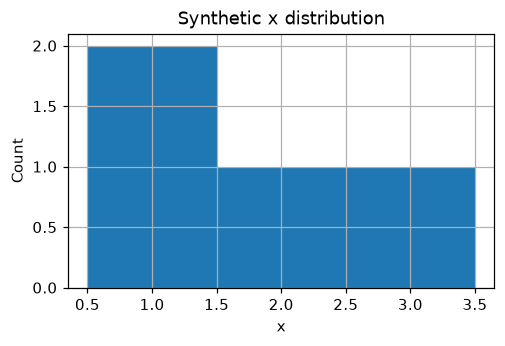

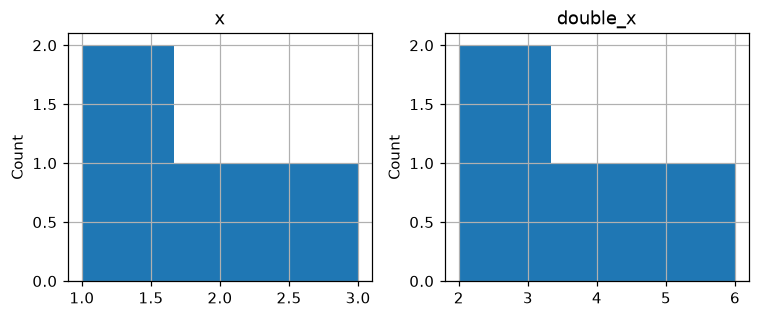

In [75]:
e27 = pd.Series([1,1,2,3], name='x')
fig27, ax27 = plt.subplots(figsize=(5,3))
e27.hist(bins=[.5,1.5,2.5,3.5],ax=ax27)
ax27.set(title='Synthetic x distribution',xlabel='x',ylabel='Count')
assert [bar.get_height() for bar in ax27.patches] == [2,1,1]
from io import BytesIO
with BytesIO() as buffer27:
    fig27.savefig(buffer27,format='png',dpi=110,bbox_inches='tight')
    display(Image(data=buffer27.getvalue()))
plt.close(fig27)
axes27 = pd.DataFrame({'x':e27,'double_x':e27*2}).hist(bins=3,figsize=(7,3))
for axis27 in axes27.ravel():
    axis27.set_ylabel('Count')
fig27b = axes27.ravel()[0].figure
fig27b.tight_layout()
with BytesIO() as buffer27b:
    fig27b.savefig(buffer27b,format='png',dpi=110,bbox_inches='tight')
    display(Image(data=buffer27b.getvalue()))
plt.close(fig27b)
assert not plt.get_fignums()